# CC2017 – Modelación y Simulación · Laboratorio 7 (entrega parcial: Tasks 1 y 2)
**Modelo híbrido System Dynamics + eventos discretos para Aula Abierta**

**Grupo $g = 7$** → $q = 0.20 + 0.05\,((7-1) \bmod 4) = 0.30$ y $D = 3 + ((7-1) \bmod 4) = 5$ días.

Convenciones: tiempo del SD en **días**, tiempo del DES en **segundos**; $\mu = 2$ sol/s por servidor; $a = 0.0005$ sol/s por usuario.
Cada bloque de código indica con qué fórmula de las diapositivas se corresponde.

## Task 1.1 – Predicciones (escritas ANTES de simular; no se modifican)

> **Predicción 1.1a — híbrido con retroalimentación vs. cascada ($\kappa_W=\kappa_R=0$).**
> Con $c=4$ y $\mu=2$, la capacidad es $c\mu=8$ sol/s y $\rho_{\text{pred}}=U/16000$. La adopción tipo Bass con $q=0.30$ lleva $U$ de 100 a $\approx 11{,}200$ (umbral $\theta=0.7$) en unos 16–17 días, y a $U\approx16{,}000$ ($\rho=1$) hacia el día 21; los servidores del primer pedido llegan 5 días después del cruce, es decir, *después* de que $\rho$ pase de 1. En la cascada espero entonces una saturación breve (días $\approx$ 20–23): latencia máxima del orden de 5–7 s (cola casi llena, $K/(c\mu)\approx 7.5$ s) y fracción rechazada máxima del 5–15 %. Al cerrar el lazo, el abandono $\kappa_W\max(0,W-0.75)$ es enorme (1 por día por segundo de exceso) y frena a $U$ cerca de $12{,}000$–$13{,}000$ mientras llegan los servidores, de modo que espero latencia máxima de $\approx1$–1.5 s y rechazos casi nulos ($<1$ %). $U(100)$: casi igual en ambos casos ($\approx 19{,}800$, es decir, $\approx 99%$ de $M$, con diferencia menor al 2 %), porque al final hay 8 servidores en los dos y el lazo solo altera el transitorio.
>
> **Predicción 1.1b — primer pedido y servidores al día 100.**
> El primer pedido se emite cuando $U$ cruza 11{,}200, hacia el **día 17** (rango 16–19); la realimentación casi no lo retrasa porque con $\rho=0.7$ la latencia M/M/4 es $\approx0.68$ s, menor que $W_{\text{ok}}=0.75$ s. Esos 2 servidores llegan hacia el día 22 ($c=6$). Con 6 servidores, $\rho_{\text{pred}}$ vuelve a cruzar 0.7 cuando $U\approx16{,}800$ (hacia el día 28–30), lo que dispara un segundo pedido y deja $c=8$ hacia el día 33–35. Con $c=8$, $\rho_{\text{max}}=20000\cdot0.0005/16=0.625<\theta$, así que no hay más pedidos: espero **8 servidores en el día 100**.
>
> **Predicción 1.1c — ventana de intercambio $H=1\to7$ días.**
> Espero que empeoren las métricas del transitorio: la latencia máxima y la fracción rechazada máxima *aumentan* con $H$, porque el SD actúa con un $W$ y un $r$ viejos (hasta 7 días) mientras $U$ crece casi 1{,}500 usuarios/día: el freno por abandono llega tarde, $U$ se pasa del equilibrio y el siguiente $W$ medido ya es alto y se mantiene días, lo que provoca una caída brusca de $U$ y posibles oscilaciones. $U(100)$ cambiará poco (la capacidad final es la misma), pero la trayectoria $U(t)$ se desvía más de la de $H$ pequeño. No espero un cambio regular (monótono) con $H$: el DES entrega una sola muestra ruidosa por ventana y su fase respecto al retraso $D=5$ días y al instante del cruce cambia con $H$, de modo que el error debe ser irregular y creciente solo en promedio. El primer pedido no depende de $H$ (el cruce se detecta sobre $U(t)$ continuo).

In [1]:
import math, random, heapq, time, json
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate, optimize

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
RES = {}            # resultados numéricos que se reportan en el informe (.tex)


def ic95(x):
    """Media e intervalo de confianza 95 % (t de Student) de una muestra de réplicas."""
    x = np.asarray(x, dtype=float)
    n = len(x)
    m = x.mean()
    h = stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / math.sqrt(n) if n > 1 else float("nan")
    return float(m), float(h)


# ---------------------------------------------------------------- parámetros
GRUPO = 7
Q = 0.20 + 0.05 * ((GRUPO - 1) % 4)      # q del grupo
D_DELAY = 3 + ((GRUPO - 1) % 4)          # D del grupo [días]
P_BASS, M_CAP, U_INIT = 0.002, 20_000, 100.0
DELTA0, KAPPA_W, KAPPA_R, W_OK = 0.003, 1.0, 0.5, 0.75
A_RATE, MU = 0.0005, 2.0                 # a [sol/s/usuario], mu [sol/s/servidor]
K_CAP, T_WIN, T_WARM = 60, 720.0, 120.0
THETA, C0, BATCH = 0.7, 4, 2
H_INT = 0.05                             # paso de integración RK4 [días]; se justifica en el Task 2.2b
print(f"g={GRUPO}: q={Q:.2f}, D={D_DELAY} días")

g=7: q=0.30, D=5 días


## Teoría de colas (referencia para verificar el DES)
Fórmulas de la sesión: $A=\lambda/\mu$, $\rho=A/c$,
$C(c,A)=\dfrac{\frac{A^c}{c!}\frac{1}{1-\rho}}{\sum_{k<c}\frac{A^k}{k!}+\frac{A^c}{c!}\frac{1}{1-\rho}}$,
$W_q=\dfrac{C}{c\mu-\lambda}$, $W=W_q+\dfrac1\mu$, y Little: $L=\lambda W$, $L_q=\lambda W_q$.
Para M/M/$c$/$K$: $\pi_n\propto\prod_{i\le n}\frac{\lambda}{\min(i,c)\mu}$, bloqueo $r=\pi_K$, $\lambda_{ef}=\lambda(1-\pi_K)$.

In [2]:
def erlang_c(c, A):
    """P(esperar) de Erlang C: [A^c/c! 1/(1-rho)] / [sum_{k<c} A^k/k! + A^c/c! 1/(1-rho)], rho=A/c<1."""
    rho = A / c
    top = A**c / math.factorial(c) / (1 - rho)
    return top / (sum(A**k / math.factorial(k) for k in range(c)) + top)


def mmc_theory(lam, c, mu=MU):
    """Fórmulas de M/M/c (K infinito): Wq = C/(c mu - lam), W = Wq + 1/mu, L = lam W (Little)."""
    A = lam / mu
    C = erlang_c(c, A)
    Wq = C / (c * mu - lam)
    W = Wq + 1 / mu
    return dict(A=A, rho=A / c, C=C, Wq=Wq, W=W, L=lam * W, Lq=lam * Wq, util=A / c)


def mmcK_pi(lam, c, K, mu=MU):
    """Distribución estacionaria de M/M/c/K: pi_n propto prod_{i<=n} lam/(min(i,c) mu)."""
    w = np.empty(K + 1)
    w[0] = 1.0
    for n in range(1, K + 1):
        w[n] = w[n - 1] * lam / (min(n, c) * mu)
    return w / w.sum()


def mmcK_theory(lam, c, K, mu=MU):
    """Medidas exactas de M/M/c/K: r = pi_K, lam_ef = lam (1-pi_K), W = L/lam_ef (Little)."""
    pi = mmcK_pi(lam, c, K, mu)
    n = np.arange(K + 1)
    L = float((n * pi).sum())
    Lq = float((np.maximum(n - c, 0) * pi).sum())
    lam_ef = lam * (1 - pi[K])
    busy = float((np.minimum(n, c) * pi).sum())
    return dict(r=float(pi[K]), lam_ef=float(lam_ef), L=L, Lq=Lq, W=L / lam_ef, Wq=Lq / lam_ef,
                util=busy / c, busy=busy)


# Verificación cruzada de la fórmula de Erlang C con la recursión de Erlang B (numéricamente estable)
def erlang_c_recursion(c, A):
    B = 1.0
    for k in range(1, c + 1):
        B = A * B / (k + A * B)
    return c * B / (c - A * (1 - B))

assert abs(erlang_c(4, 3.0) - erlang_c_recursion(4, 3.0)) < 1e-12
print("C(4,3) =", erlang_c(4, 3.0))

C(4,3) = 0.5094339622641509


## Capa DES: cola M/M/$c$/$K$ con eventos discretos
Eventos: **llegada** (Poisson, tasa $\lambda=aU$) y **fin de servicio** (Exp($\mu$)). Cola FIFO, bloqueo si hay $K$ dentro.

*Regla de la ventana (se justifica en 2.4c):* se mide lo que **llega** en $[120,720)$ s ("solicitudes marcadas"); la ventana arranca con una ocupación
muestreada de la distribución estacionaria de M/M/$c$/$K$ (opción `init='stationary'`) **y además** se descartan los primeros 120 s;
tras $T=720$ s se sigue simulando hasta que salgan todas las marcadas (sin censura a la derecha).

In [3]:
def des_window(lam, c, rng, K=K_CAP, mu=MU, T=T_WIN, warm=T_WARM, init="stationary"):
    """Simula una ventana de hora pico de la cola M/M/c/K con eventos discretos.

    Devuelve W (tiempo en el sistema), Wq (espera), r (fracción rechazada), utilización y conteos para
    verificar Little y la conservación de entidades (N0 + A = S + R + N_T).
    init: 'stationary' (ocupación inicial ~ pi de M/M/c/K) | 'empty' (sistema vacío).
    """
    if lam <= 0:
        return dict(W=1 / mu, Wq=0.0, r=0.0, util=0.0, L=0.0, Lq=0.0, lam_ef=0.0, n_arr=0, n_acc=0,
                    n_rej=0, n_serv=0, n_in=0, N0=0, A_all=0, S_all=0, R_all=0, N_T=0)
    expo = rng.expovariate
    heap = []                      # servicios en curso: (t_salida, t_llegada, t_inicio_servicio)
    queue = deque()                # llegadas en espera (FIFO)
    n0 = 0
    if init == "stationary":
        u, acc = rng.random(), 0.0
        pi = mmcK_pi(lam, c, K, mu)
        for n0 in range(K + 1):
            acc += pi[n0]
            if u <= acc:
                break
    for i in range(n0):            # los que ya estaban no se marcan (t_llegada=-1); sin memoria => Exp(mu)
        if i < c:
            heapq.heappush(heap, (expo(mu), -1.0, 0.0))
        else:
            queue.append(-1.0)
    t, t_arr = 0.0, expo(lam)
    ar_n = ar_busy = ar_q = 0.0    # áreas bajo n(t), busy(t), q(t) en [warm, T]  (para L, Lq y utilización)
    A_all = S_all = R_all = 0      # conteos de toda la ventana [0, T]
    n_arr = n_rej = n_serv_T = 0   # conteos de solicitudes marcadas
    tag_in = 0                     # marcadas dentro del sistema
    Wsum = Wqsum = 0.0
    n_done = 0
    snap = None
    INF = float("inf")
    while True:
        t_dep = heap[0][0] if heap else INF
        te = t_arr if t_arr < t_dep else t_dep
        lo, hi = (t if t > warm else warm), (te if te < T else T)
        if hi > lo:                # integra el estado entre eventos dentro de la parte medida
            dt = hi - lo
            b = len(heap)
            ar_n += (b + len(queue)) * dt
            ar_busy += b * dt
            ar_q += len(queue) * dt
        t = te
        if snap is None and te > T:   # foto del estado exactamente en t = T
            snap = dict(n_arr=n_arr, n_rej=n_rej, n_serv=n_serv_T, n_in=tag_in, A_all=A_all,
                        S_all=S_all, R_all=R_all, N_T=len(heap) + len(queue))
        if snap is not None and tag_in == 0:
            break
        if te == t_arr:            # ---- evento: llegada
            tagged = warm <= te < T
            if te < T:
                A_all += 1
            if tagged:
                n_arr += 1
            if len(heap) + len(queue) >= K:          # sistema lleno => rechazo
                if te < T:
                    R_all += 1
                if tagged:
                    n_rej += 1
            else:
                if tagged:
                    tag_in += 1
                if len(heap) < c:                    # hay servidor libre
                    heapq.heappush(heap, (te + expo(mu), te, te))
                else:
                    queue.append(te)
            t_arr = te + expo(lam)
        else:                      # ---- evento: fin de servicio
            _, a_i, s_i = heapq.heappop(heap)
            if te <= T:
                S_all += 1
            if warm <= a_i < T:
                tag_in -= 1
                n_done += 1
                Wsum += te - a_i
                Wqsum += s_i - a_i
                if te <= T:
                    n_serv_T += 1
            if queue:
                a_q = queue.popleft()
                heapq.heappush(heap, (te + expo(mu), a_q, te))
    dur = T - warm
    n_acc = snap["n_arr"] - snap["n_rej"]
    return dict(W=Wsum / n_done if n_done else 1 / mu, Wq=Wqsum / n_done if n_done else 0.0,
                r=snap["n_rej"] / snap["n_arr"] if snap["n_arr"] else 0.0,
                util=ar_busy / (c * dur), L=ar_n / dur, Lq=ar_q / dur, lam_ef=n_acc / dur,
                n_acc=n_acc, N0=n0, **snap)

## Capa SD: Bass con abandono, integradores y solución analítica
$\dfrac{dU}{dt}=(p+qU/M)(M-U)-\delta U$. Con $\delta$ constante la ecuación es una Riccati/logística:
$\dot U=-a_2(U-U_+)(U-U_-)$, $a_2=q/M$, $a_1=q-p-\delta$, $a_0=pM$, y $\frac{U-U_+}{U-U_-}=C\,e^{-\sqrt{a_1^2+4a_2a_0}\,t}$.
Esa solución cerrada es la "verdad" contra la que se mide el error de Euler/RK4 en el Task 2.2.

In [4]:
def f_sd(U, delta, q=Q):
    """dU/dt = (p + q U/M)(M - U) - delta U : adopción (innovación + boca a boca, Bass) menos abandono."""
    return (P_BASS + q * U / M_CAP) * (M_CAP - U) - delta * U


def euler_step(f, U, h):
    """Euler explícito (orden 1): U_{n+1} = U_n + h f(U_n)."""
    return U + h * f(U)


def rk4_step(f, U, h):
    """Runge-Kutta clásico de orden 4: U_{n+1} = U_n + h/6 (k1 + 2 k2 + 2 k3 + k4)."""
    k1 = f(U)
    k2 = f(U + 0.5 * h * k1)
    k3 = f(U + 0.5 * h * k2)
    k4 = f(U + h * k3)
    return U + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6.0


def integrar(step, f, U0, T, h):
    """Integra con paso fijo h hasta T; devuelve (t, U)."""
    n = int(round(T / h))
    t = np.linspace(0.0, n * h, n + 1)
    U = np.empty(n + 1)
    U[0] = U0
    for i in range(n):
        U[i + 1] = step(f, U[i], h)
    return t, U


def bass_exacta(t, delta=DELTA0, q=Q, U0=U_INIT):
    """Solución analítica de dU/dt = (p+qU/M)(M-U) - delta U con delta constante."""
    a2, a1, a0 = q / M_CAP, q - P_BASS - delta, P_BASS * M_CAP
    disc = math.sqrt(a1 * a1 + 4 * a2 * a0)
    Up, Um = (a1 + disc) / (2 * a2), (a1 - disc) / (2 * a2)
    C = (U0 - Up) / (U0 - Um)
    E = C * np.exp(-disc * np.asarray(t))
    return (Up - Um * E) / (1 - E)


def rho_pred(U, c, a=A_RATE, mu=MU):
    """Utilización prevista: rho_pred = a U / (c mu)."""
    return a * U / (c * mu)

## Híbrido: SD + DES + autoescalado como evento de estado
* **Intercambio** cada $H$ días (en $t=kH$): $\lambda=aU$, $c$ → DES → $(W,r)$ que el SD mantiene constantes hasta el siguiente intercambio.
* **Evento de estado** $g(t)=\rho_{pred}(t)-\theta$: `detect='exact'` localiza el cruce hacia arriba **dentro** del paso por bisección sobre RK4;
  `detect='naive'` solo revisa $g$ al final de cada $\Delta t$ (`check_dt`).
* **Evento de tiempo**: el paso se corta exactamente en el instante en que llegan los servidores; allí $c\mathrel{+}=2$ y, si $\rho_{pred}>\theta$, se reordena de inmediato.
* Números aleatorios comunes: la ventana $k$ usa `Random(seed*1_000_003 + k)`, así las variantes se comparan con el mismo ruido del DES.

In [5]:
def simular_hibrido(H=1.0, T_end=100.0, c0=C0, theta=THETA, batch=BATCH, delay=D_DELAY,
                    kappa_w=KAPPA_W, kappa_r=KAPPA_R, q=Q, h=H_INT, detect="exact",
                    check_dt=1.0, seed=0, des_init="stationary"):
    eps = 1e-9
    t, U, c = 0.0, U_INIT, c0
    pending = None                 # instante de llegada del pedido pendiente
    orders, arrivals = [], []      # (t_pedido, motivo) y t_llegada de servidores
    k_ex, W, r = 0, 0.0, 0.0
    next_ex = 0.0
    next_chk = check_dt
    prev_g = chk_prev = rho_pred(U, c) - theta   # chk_prev: g en la última revisión (versión ingenua)
    log = []                       # (t, U, c, lam, W, r, n_arr, n_rej) en cada intercambio
    tr_t, tr_U, tr_c = [0.0], [U], [c]
    while t < T_end - eps:
        if t >= next_ex - eps:     # ---- intercambio SD -> DES -> SD
            res = des_window(A_RATE * U, c, random.Random(seed * 1_000_003 + k_ex), init=des_init)
            W, r = res["W"], res["r"]
            log.append((t, U, c, A_RATE * U, W, r, res["n_arr"], res["n_rej"]))
            k_ex += 1
            next_ex = k_ex * H
        delta = DELTA0 + kappa_w * max(0.0, W - W_OK) + kappa_r * r     # abandono con (W, r) sostenidos
        f = lambda u: f_sd(u, delta, q)
        t_stop = min(next_ex, T_end, t + h)
        if pending is not None:
            t_stop = min(t_stop, pending)           # el evento de tiempo corta el paso
        if detect == "naive":
            t_stop = min(t_stop, next_chk)
        hh = t_stop - t
        U_new = rk4_step(f, U, hh)
        if detect == "exact" and pending is None:
            g_new = rho_pred(U_new, c) - theta
            if prev_g < 0.0 <= g_new:                       # cruce hacia arriba dentro del paso
                lo, hi = 0.0, hh
                for _ in range(60):                         # bisección en tau: RK4 de tamaño tau desde (t, U)
                    mid = 0.5 * (lo + hi)
                    if rho_pred(rk4_step(f, U, mid), c) - theta < 0.0:
                        lo = mid
                    else:
                        hi = mid
                te = t + hi
                pending = te + delay
                orders.append((te, "cruce"))
        t, U = t_stop, U_new
        g = rho_pred(U, c) - theta
        if detect == "naive" and abs(t - next_chk) < eps:   # revisión solo al final del paso Delta t
            if pending is None and chk_prev < 0.0 <= g:
                pending = t + delay
                orders.append((t, "cruce"))
            chk_prev = g
            next_chk += check_dt
        prev_g = g
        if pending is not None and abs(t - pending) < eps:  # ---- evento de tiempo: llegan los servidores
            c += batch
            arrivals.append(t)
            pending = None
            prev_g = chk_prev = rho_pred(U, c) - theta
            if prev_g > 0.0:                                # regla del reorden inmediato
                pending = t + delay
                orders.append((t, "reorden"))
        tr_t.append(t); tr_U.append(U); tr_c.append(c)
    return dict(t=np.array(tr_t), U=np.array(tr_U), c=np.array(tr_c), log=log, orders=orders,
                arrivals=arrivals, U_end=U, c_end=c,
                W_max=max(x[4] for x in log), r_max=max(x[5] for x in log))


t0 = time.time()
demo = simular_hibrido(seed=0)
print(f"una réplica de 100 días: {time.time()-t0:.1f} s | pedidos: {[(round(a,3),b) for a,b in demo['orders']]}")

una réplica de 100 días: 0.9 s | pedidos: [(15.738, 'cruce'), (26.446, 'cruce')]


---
# Task 1.2 – Equilibrio del lazo con capacidad fija ($c=4$, sin rechazos)

**(a)** $A=aU/\mu=0.00025\,U$, $W(U)=\dfrac{C(4,A)}{4\mu-aU}+\dfrac1\mu$, válida para $aU<c\mu=8$, es decir $U<16{,}000$ ($\rho<1$).

**(b)** Equilibrio: $(p+qU^*/M)(M-U^*)=\big[\delta_0+\kappa_W\max(0,W(U^*)-W_{ok})\big]U^*$ (con $r=0$).

raíces en (0,16000): 1
{'n_raices': 1, 'U_star': 12715.50788, 'rho_star': 0.79472, 'W_star': 0.85741, 'C_star': 0.58696, 'A_star': 3.17888, 'PK_star': 0.0, 'W_K_star': np.float64(0.8574), 'adop': 1403.95924, 'aband': 1403.95924, 'U_star_K': 12715.5643}
integración cuasi-estática: U(300) = 12715.51 (U* = 12715.51); alcanza 95% de U* en t = 16.4 d


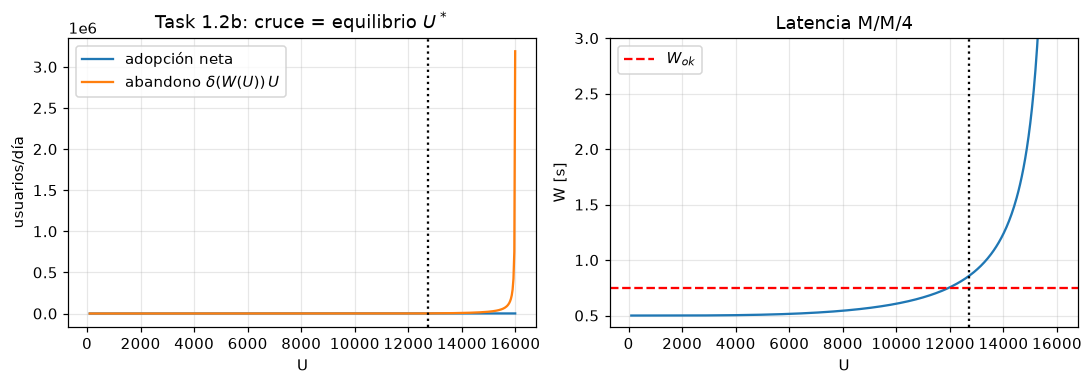

In [6]:
def W_mmc(U, c=4):
    """Latencia de M/M/c (a): W = C(c,A)/(c mu - a U) + 1/mu, con A = a U/mu. Válida para a U < c mu."""
    return mmc_theory(A_RATE * U, c)["W"]


def adopcion_neta(U):
    """Adopción: (p + q U/M)(M - U)."""
    return (P_BASS + Q * U / M_CAP) * (M_CAP - U)


def abandono(U, c=4):
    """Abandono con latencia de equilibrio y r = 0: [delta0 + kW max(0, W-Wok)] U."""
    return (DELTA0 + KAPPA_W * max(0.0, W_mmc(U, c) - W_OK)) * U


def residuo(U, c=4):
    return adopcion_neta(U) - abandono(U, c)

# Barrido de signos para confirmar que la raíz es única en (0, 16000)
grid = np.linspace(1, 15_999, 4000)
vals = np.array([residuo(u) for u in grid])
cambios = np.where(np.sign(vals[:-1]) != np.sign(vals[1:]))[0]
U_star = optimize.brentq(residuo, 1_000, 15_990, xtol=1e-9)
W_star = W_mmc(U_star)
rho_star = rho_pred(U_star, 4)
th_K = mmcK_theory(A_RATE * U_star, 4, K_CAP)
RES["t12"] = dict(n_raices=int(len(cambios)), U_star=U_star, rho_star=rho_star, W_star=W_star,
                  C_star=erlang_c(4, A_RATE * U_star / MU), A_star=A_RATE * U_star / MU,
                  PK_star=th_K["r"], W_K_star=th_K["W"],
                  adop=float(adopcion_neta(U_star)), aband=float(abandono(U_star)))
# Con M/M/4/60 y rechazos (r = pi_K) el equilibrio casi no cambia
def residuo_K(U):
    th = mmcK_theory(A_RATE * U, 4, K_CAP)
    return adopcion_neta(U) - (DELTA0 + KAPPA_W * max(0, th["W"] - W_OK) + KAPPA_R * th["r"]) * U
RES["t12"]["U_star_K"] = optimize.brentq(residuo_K, 1_000, 15_990, xtol=1e-9)
print("raíces en (0,16000):", len(cambios))
print({k: (round(v, 5) if isinstance(v, float) else v) for k, v in RES["t12"].items()})

# Comprobación independiente: integrar el SD con la latencia cuasi-estática W(U) (c=4, r=0) desde U(0)=100;
# si el análisis es correcto, U(t) converge a U* desde abajo y se queda ahí.
def f_cuasi(U):
    return f_sd(U, DELTA0 + KAPPA_W * max(0.0, W_mmc(min(U, 15_999)) - W_OK))
t_q, U_q = integrar(rk4_step, f_cuasi, U_INIT, 300, 0.05)
RES["t12"]["U_cuasi_300d"] = float(U_q[-1])
RES["t12"]["t_cuasi_95"] = float(t_q[np.argmax(U_q >= 0.95 * U_star)])
print(f"integración cuasi-estática: U(300) = {U_q[-1]:.2f} (U* = {U_star:.2f}); alcanza 95% de U* en t = {RES['t12']['t_cuasi_95']:.1f} d")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
U_g = np.linspace(100, 15_990, 500)
ax[0].plot(U_g, [adopcion_neta(u) for u in U_g], label="adopción neta")
ax[0].plot(U_g, [abandono(u) for u in U_g], label="abandono $\\delta(W(U))\\,U$")
ax[0].axvline(U_star, color="k", ls=":"); ax[0].set(xlabel="U", ylabel="usuarios/día", title="Task 1.2b: cruce = equilibrio $U^*$")
ax[0].legend()
ax[1].plot(U_g, [W_mmc(u) for u in U_g]); ax[1].axhline(W_OK, color="r", ls="--", label="$W_{ok}$")
ax[1].axvline(U_star, color="k", ls=":"); ax[1].set(xlabel="U", ylabel="W [s]", title="Latencia M/M/4", ylim=(0.4, 3)); ax[1].legend()
plt.tight_layout(); plt.show()

---
# Task 1.3 – Línea base generada por la IA (sin modificar)
El prompt exacto y el código tal como se recibió están en el **Anexo A** del informe (.tex) y se repiten aquí.
El código se ejecuta en un espacio de nombres aislado (`exec`) para que no pise las variables de este cuaderno.

In [7]:
BASELINE_PROMPT = r'''Eres un agente que escribe y ejecuta código. Implementa en Python (numpy/scipy) el siguiente modelo híbrido de System Dynamics + simulación de eventos discretos, ejecútalo y repórtame los resultados.

CONTEXTO. Aula Abierta es una plataforma de video educativo que crece por boca a boca. Se debe decidir la política de crecimiento de servidores. El modelo combina dos paradigmas acoplados en ambos sentidos: los usuarios activos evolucionan con System Dynamics y el clúster de servidores se simula con eventos discretos.

CAPA SD (usuarios activos U(t), tiempo en días):
dU/dt = (p + q U/M)(M - U) - delta U,  con  delta = delta0 + kappaW * max(0, W - Wok) + kappaR * r
W es la latencia (segundos) y r la fracción de solicitudes rechazadas que percibe el usuario.
Valores: p = 0.002 por día, q = 0.30, M = 20000, U(0) = 100, delta0 = 0.003 por día, kappaW = 1.0 por día por segundo, kappaR = 0.5 por día, Wok = 0.75 s.

CAPA DES (clúster en la hora pico): cola M/M/c/K. Las solicitudes llegan como proceso de Poisson de tasa lambda = a U, con a = 0.0005 solicitudes por segundo por usuario activo. Cada servidor atiende con tiempo exponencial de media 0.5 s (mu = 2 por segundo). El sistema admite como máximo K = 60 solicitudes simultáneas; si está lleno, la solicitud nueva se rechaza. Cada vez que el SD necesita datos del DES, este simula 720 segundos de hora pico con la tasa y los servidores vigentes, descarta los primeros 120 segundos como calentamiento y devuelve la latencia promedio W de las solicitudes aceptadas (tiempo en el sistema) y la fracción rechazada r.

POLÍTICA DE AUTOESCALADO: sea rho_pred(t) = a U(t) / (c mu). Cuando rho_pred cruza hacia arriba el umbral theta = 0.7 y no hay un pedido pendiente, se ordenan 2 servidores que llegan D = 5 días después. Si al llegar rho_pred sigue por encima de theta, se ordena otro pedido de inmediato. Al inicio hay c(0) = 4 servidores.

ACOPLAMIENTO: cada H días el SD entrega al DES la tasa lambda = a U y el número de servidores c; el DES devuelve W y r, que el SD mantiene constantes hasta el siguiente intercambio. Valor base: H = 1 día.

TAREA: simula UNA réplica de 100 días con H = 1 y c(0) = 4. Reporta U(100), el número final de servidores, la latencia máxima W y la fracción máxima de solicitudes rechazadas r observadas. Entrega el código completo y dime si los resultados son correctos.'''
print(BASELINE_PROMPT)

Eres un agente que escribe y ejecuta código. Implementa en Python (numpy/scipy) el siguiente modelo híbrido de System Dynamics + simulación de eventos discretos, ejecútalo y repórtame los resultados.

CONTEXTO. Aula Abierta es una plataforma de video educativo que crece por boca a boca. Se debe decidir la política de crecimiento de servidores. El modelo combina dos paradigmas acoplados en ambos sentidos: los usuarios activos evolucionan con System Dynamics y el clúster de servidores se simula con eventos discretos.

CAPA SD (usuarios activos U(t), tiempo en días):
dU/dt = (p + q U/M)(M - U) - delta U,  con  delta = delta0 + kappaW * max(0, W - Wok) + kappaR * r
W es la latencia (segundos) y r la fracción de solicitudes rechazadas que percibe el usuario.
Valores: p = 0.002 por día, q = 0.30, M = 20000, U(0) = 100, delta0 = 0.003 por día, kappaW = 1.0 por día por segundo, kappaR = 0.5 por día, Wok = 0.75 s.

CAPA DES (clúster en la hora pico): cola M/M/c/K. Las solicitudes llegan como pr

In [8]:
# ===== CÓDIGO ORIGINAL DE LA IA (sin modificar) =====
BASELINE_SRC = r'''import heapq
import numpy as np
from scipy.integrate import solve_ivp

np.random.seed(42)

# --- Parámetros ---
p, q, M = 0.002, 0.30, 20000
U0 = 100.0
delta0, kappaW, kappaR, Wok = 0.003, 1.0, 0.5, 0.75
a, mu, K = 0.0005, 2.0, 60
T_sim, T_warm = 720.0, 120.0
theta, batch, D, c0 = 0.7, 2, 5, 4
H = 1.0
T_end = 100


def simulate_des(lam, c):
    """Simula M/M/c/K durante T_sim segundos y devuelve (W, r) tras el calentamiento."""
    t = 0.0
    free = [0.0] * c               # instante en que se libera cada servidor
    heapq.heapify(free)
    in_system = []                 # tiempos de salida de las solicitudes aceptadas
    lat, acc, rej = [], 0, 0
    while True:
        t += np.random.exponential(1.0 / lam)
        if t > T_sim:
            break
        while in_system and in_system[0] <= t:
            heapq.heappop(in_system)
        if len(in_system) >= K:
            if t >= T_warm:
                rej += 1
            continue
        start = max(t, heapq.heappop(free))
        done = start + np.random.exponential(1.0 / mu)
        heapq.heappush(free, done)
        heapq.heappush(in_system, done)
        if t >= T_warm:
            acc += 1
            lat.append(done - t)
    W = np.mean(lat) if lat else 0.0
    r = rej / (rej + acc) if (rej + acc) > 0 else 0.0
    return W, r


def dUdt(t, U, delta):
    return (p + q * U / M) * (M - U) - delta * U


# --- Simulación híbrida ---
U = U0
c = c0
pending = None          # día en que llegan los servidores pedidos
rho_prev = a * U / (c * mu)
Ws, rs, Us, cs = [], [], [U], [c]

for day in range(T_end):
    # llegada de servidores
    if pending is not None and day >= pending:
        c += batch
        pending = None
        if a * U / (c * mu) > theta:
            pending = day + D

    # intercambio SD -> DES -> SD
    W, r = simulate_des(a * U, c)
    Ws.append(W)
    rs.append(r)

    delta = delta0 + kappaW * max(0, W - Wok) + kappaR * r
    sol = solve_ivp(dUdt, [day, day + H], [U], args=(delta,))
    U = sol.y[0, -1]

    # política de autoescalado
    rho = a * U / (c * mu)
    if rho > theta and rho_prev <= theta and pending is None:
        pending = day + 1 + D
    rho_prev = rho

    Us.append(U)
    cs.append(c)

print("U(100) =", round(U, 1))
print("Servidores finales =", c)
print("Latencia máxima W =", round(max(Ws), 3), "s")
print("Fracción máxima rechazada r =", round(max(rs), 4))
'''
# ====================================================

In [9]:
ns_base = {}
exec(compile(BASELINE_SRC, "baseline_ia.py", "exec"), ns_base)     # 1 réplica, H=1, c(0)=4, 100 días
RES["t13"] = dict(U100=float(ns_base["U"]), c_end=int(ns_base["c"]),
                  W_max=float(max(ns_base["Ws"])), r_max=float(max(ns_base["rs"])))
print(RES["t13"])

U(100) = 19801.3
Servidores finales = 8
Latencia máxima W = 0.958 s
Fracción máxima rechazada r = 0.0
{'U100': 19801.33770227898, 'c_end': 8, 'W_max': 0.9578499982556427, 'r_max': 0.0}


---
# Task 2.1 – Verificación de la capa DES contra la teoría (sin SD)

In [10]:
def ic_cubre(m, h, ref):
    return bool(m - h <= ref <= m + h)

# (a) lambda=6, c=4, K muy grande (10^9), 40 réplicas independientes de 720 s con calentamiento de 120 s,
#     sistema inicialmente vacío (se verifica el motor del DES tal cual lo define el enunciado).
N_REP = 40
rep_a = [des_window(6.0, 4, random.Random(21_000 + i), K=10**9, init="empty") for i in range(N_REP)]
th_a = mmc_theory(6.0, 4)
tab_a = {}
for nombre, clave, ref in [("W (latencia)", "W", th_a["W"]), ("Wq (espera en cola)", "Wq", th_a["Wq"]),
                           ("Utilización", "util", th_a["util"])]:
    m, h = ic95([r[clave] for r in rep_a])
    tab_a[clave] = dict(sim=m, ic=h, teoria=ref, cubre=ic_cubre(m, h, ref), err_rel=(m - ref) / ref)
    print(f"{nombre:22s} sim={m:.4f} ± {h:.4f}   teoría={ref:.4f}   IC cubre teoría: {ic_cubre(m, h, ref)}")
RES["t21a"] = dict(n=N_REP, tab=tab_a, theory=th_a)

# (b) lambda=10, c=4, K=60: sobrecarga. r simulada vs. aproximación 1 - c mu / lambda y vs. valor exacto pi_K
rep_b = [des_window(10.0, 4, random.Random(22_000 + i), init="empty") for i in range(N_REP)]
m_r, h_r = ic95([r["r"] for r in rep_b])
approx = 1 - 4 * MU / 10.0
exacto = mmcK_theory(10.0, 4, K_CAP)
RES["t21b"] = dict(r_sim=m_r, r_ic=h_r, approx=approx, exacto=exacto["r"], W_sim=ic95([r["W"] for r in rep_b]),
                   W_exacto=exacto["W"])
print(f"r simulada = {m_r:.4f} ± {h_r:.4f} | 1-c mu/lam = {approx:.4f} | exacto pi_K = {exacto['r']:.7f}")

# Por qué es aproximación: lam_ef = lam (1 - r) = mu E[servidores ocupados] <= c mu  =>  r >= 1 - c mu / lam
# con igualdad solo si todos los servidores están ocupados siempre. Se mide el error al acercarse a rho = 1.
filas_b = []
for lam in [8.4, 9.0, 10.0, 12.0, 20.0]:
    ex = mmcK_theory(lam, 4, K_CAP)
    filas_b.append(dict(lam=lam, rho=lam / 8, approx=max(0.0, 1 - 8 / lam), exacto=ex["r"], busy=ex["busy"]))
    print(f"lam={lam:5.1f} rho={lam/8:.3f} aprox={max(0.0,1-8/lam):.5f} exacto={ex['r']:.5f} servidores ocupados E[b]={ex['busy']:.4f}")
RES["t21b"]["filas"] = filas_b

# (c) Ley de Little con las cantidades medidas en cada réplica: L = lam_ef W, Lq = lam_ef Wq, E[ocupados] = lam_ef / mu
def little(reps, c):
    out = {}
    for nombre, medida, pred in [
        ("L = lam_ef W", lambda r: r["L"], lambda r: r["lam_ef"] * r["W"]),
        ("Lq = lam_ef Wq", lambda r: r["Lq"], lambda r: r["lam_ef"] * r["Wq"]),
        ("c*util = lam_ef/mu", lambda r: c * r["util"], lambda r: r["lam_ef"] / MU)]:
        err = np.array([(pred(r) - medida(r)) / medida(r) for r in reps])
        m, h = ic95(err)
        ma, ha = ic95(np.abs(err))
        out[nombre] = dict(err_rel_medio=m, ic=h, abs_medio=ma, abs_ic=ha, medida=float(np.mean([medida(r) for r in reps])),
                           pred=float(np.mean([pred(r) for r in reps])))
        print(f"{nombre:20s} L_medido={out[nombre]['medida']:.4f} L_Little={out[nombre]['pred']:.4f}  err_rel medio={m*100:.3f}% ± {h*100:.3f}%  |err| medio={ma*100:.3f}%")
    return out
print("(a) K grande, lam=6"); RES["t21c_a"] = little(rep_a, 4)
print("(b) K=60, lam=10");    RES["t21c_b"] = little(rep_b, 4)

W (latencia)           sim=0.7552 ± 0.0158   teoría=0.7547   IC cubre teoría: True
Wq (espera en cola)    sim=0.2572 ± 0.0141   teoría=0.2547   IC cubre teoría: True
Utilización            sim=0.7471 ± 0.0046   teoría=0.7500   IC cubre teoría: True


r simulada = 0.2022 ± 0.0044 | 1-c mu/lam = 0.2000 | exacto pi_K = 0.2000004
lam=  8.4 rho=1.050 aprox=0.04762 exacto=0.05043 servidores ocupados E[b]=3.9882
lam=  9.0 rho=1.125 aprox=0.11111 exacto=0.11122 servidores ocupados E[b]=3.9995
lam= 10.0 rho=1.250 aprox=0.20000 exacto=0.20000 servidores ocupados E[b]=4.0000
lam= 12.0 rho=1.500 aprox=0.33333 exacto=0.33333 servidores ocupados E[b]=4.0000
lam= 20.0 rho=2.500 aprox=0.60000 exacto=0.60000 servidores ocupados E[b]=4.0000
(a) K grande, lam=6
L = lam_ef W         L_medido=4.5329 L_Little=4.5310  err_rel medio=-0.044% ± 0.053%  |err| medio=0.123%
Lq = lam_ef Wq       L_medido=1.5445 L_Little=1.5437  err_rel medio=-0.062% ± 0.071%  |err| medio=0.118%
c*util = lam_ef/mu   L_medido=2.9884 L_Little=2.9991  err_rel medio=0.380% ± 0.498%  |err| medio=1.276%
(b) K=60, lam=10
L = lam_ef W         L_medido=56.0082 L_Little=56.0384  err_rel medio=0.054% ± 0.051%  |err| medio=0.129%
Lq = lam_ef Wq       L_medido=52.0082 L_Little=52.0342  err_r

---
# Task 2.2 – Verificación de la capa SD (abandono constante $\delta_0$)

h=0.5: max|RK4-solve_ivp|=4.509e-02  max|RK4-exacta|=4.509e-02  max|solve_ivp-exacta|=1.826e-06  U(100): RK4=19801.337703 ivp=19801.337703
h=0.05: max|RK4-solve_ivp|=5.477e-06  max|RK4-exacta|=4.945e-06  max|solve_ivp-exacta|=1.977e-06  U(100): RK4=19801.337703 ivp=19801.337703


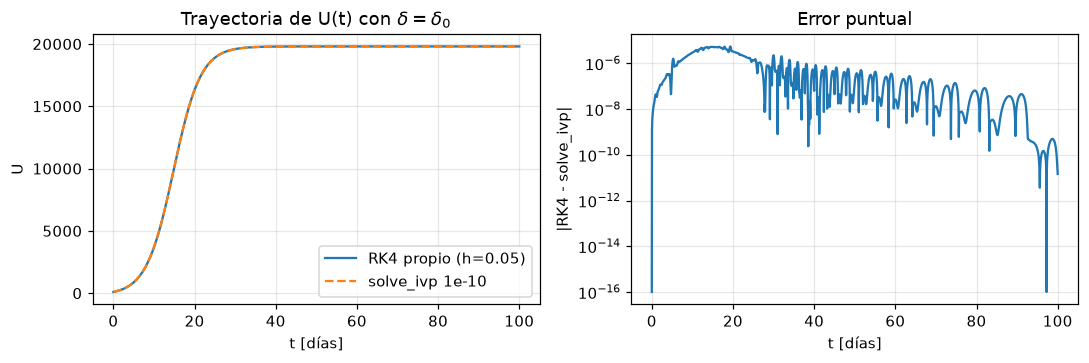

In [11]:
# (a) RK4 propio vs solve_ivp (DOP853, rtol=atol=1e-10) vs solución analítica, 100 días
f0 = lambda u: f_sd(u, DELTA0)
sol = integrate.solve_ivp(lambda t, u: [f_sd(u[0], DELTA0)], (0, 100), [U_INIT], method="DOP853",
                          rtol=1e-10, atol=1e-10, dense_output=True)
res22a = {}
for h in [0.5, H_INT]:
    t_r, U_r = integrar(rk4_step, f0, U_INIT, 100, h)
    U_ivp = sol.sol(t_r)[0]
    U_ex = bass_exacta(t_r)
    res22a[h] = dict(max_vs_ivp=float(np.max(np.abs(U_r - U_ivp))), max_vs_exacta=float(np.max(np.abs(U_r - U_ex))),
                     U100_rk4=float(U_r[-1]), U100_ivp=float(U_ivp[-1]), U100_exacta=float(U_ex[-1]),
                     ivp_vs_exacta=float(np.max(np.abs(U_ivp - U_ex))))
    print(f"h={h}: max|RK4-solve_ivp|={res22a[h]['max_vs_ivp']:.3e}  max|RK4-exacta|={res22a[h]['max_vs_exacta']:.3e}  "
          f"max|solve_ivp-exacta|={res22a[h]['ivp_vs_exacta']:.3e}  U(100): RK4={res22a[h]['U100_rk4']:.6f} ivp={res22a[h]['U100_ivp']:.6f}")
RES["t22a"] = {str(k): v for k, v in res22a.items()}
RES["t22a"]["nfev_ivp"] = int(sol.nfev)

t_r, U_r = integrar(rk4_step, f0, U_INIT, 100, H_INT)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(t_r, U_r, label=f"RK4 propio (h={H_INT})"); ax[0].plot(t_r, sol.sol(t_r)[0], "--", label="solve_ivp 1e-10")
ax[0].set(xlabel="t [días]", ylabel="U", title="Trayectoria de U(t) con $\\delta=\\delta_0$"); ax[0].legend()
ax[1].semilogy(t_r, np.abs(U_r - sol.sol(t_r)[0]) + 1e-16); ax[1].set(xlabel="t [días]", ylabel="|RK4 - solve_ivp|", title="Error puntual")
plt.tight_layout(); plt.show()

h       Euler       RK4
4        7.205e+03  9.244e+01
2        4.195e+03  8.380e+00
1        2.214e+03  6.517e-01
0.5      1.126e+03  4.509e-02
0.25     5.677e+02  2.966e-03
0.125    2.848e+02  1.902e-04
0.0625   1.427e+02  1.204e-05
0.03125  7.138e+01  7.575e-07
orden por pares Euler: [0.78 0.92 0.98 0.99 1.   1.   1.  ]
orden por pares RK4  : [3.46 3.68 3.85 3.93 3.96 3.98 3.99]
pendiente log-log (ajuste): Euler = 0.96, RK4 = 3.86
RK4 h=0.25: error máx con delta0 = 2.966e-03 ; con delta=7 = 8.031e+00   (h*delta = 1.75, límite de estabilidad RK4 ≈ 2.78)
RK4 h=0.1: error máx con delta0 = 7.832e-05 ; con delta=7 = 9.753e-02   (h*delta = 0.70, límite de estabilidad RK4 ≈ 2.78)
RK4 h=0.05: error máx con delta0 = 4.945e-06 ; con delta=7 = 4.815e-03   (h*delta = 0.35, límite de estabilidad RK4 ≈ 2.78)


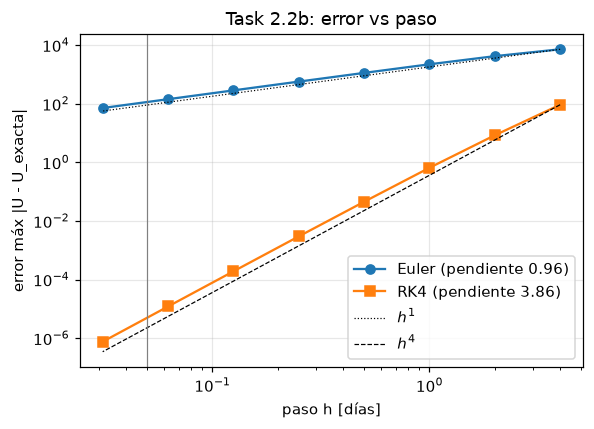

In [12]:
# (b) error máximo vs paso h (escala log-log) para Euler y RK4, con delta0 y con delta=7 (peor caso del lazo cerrado)
hs = [4, 2, 1, 0.5, 0.25, 0.125, 0.0625, 0.03125]

def errores(delta, hs):
    f = lambda u: f_sd(u, delta)
    eE, eR = [], []
    for h in hs:
        for step, lst in ((euler_step, eE), (rk4_step, eR)):
            t, U = integrar(step, f, U_INIT, 100, h)
            lst.append(float(np.max(np.abs(U - bass_exacta(t, delta)))))
    return np.array(eE), np.array(eR)

eE, eR = errores(DELTA0, hs)
orden_pares_E = [math.log2(eE[i] / eE[i + 1]) for i in range(len(hs) - 1)]
orden_pares_R = [math.log2(eR[i] / eR[i + 1]) for i in range(len(hs) - 1)]
mask_R = eR > 1e-7                                   # RK4 por debajo de ~1e-8 choca con el error de redondeo
pend_E = np.polyfit(np.log(hs), np.log(eE), 1)[0]
pend_R = np.polyfit(np.log(np.array(hs)[mask_R]), np.log(eR[mask_R]), 1)[0]
print("h       Euler       RK4")
for h, a_, b_ in zip(hs, eE, eR):
    print(f"{h:<8} {a_:.3e}  {b_:.3e}")
print("orden por pares Euler:", np.round(orden_pares_E, 2))
print("orden por pares RK4  :", np.round(orden_pares_R, 2))
print(f"pendiente log-log (ajuste): Euler = {pend_E:.2f}, RK4 = {pend_R:.2f}")

# error con el paso elegido y con delta = 7 /día
extra = {}
for h in [0.25, 0.1, H_INT]:
    e_d0 = float(np.max(np.abs(integrar(rk4_step, f0, U_INIT, 100, h)[1] - bass_exacta(integrar(rk4_step, f0, U_INIT, 100, h)[0]))))
    f7 = lambda u: f_sd(u, 7.0)
    t7, U7 = integrar(rk4_step, f7, U_INIT, 100, h)
    e_d7 = float(np.max(np.abs(U7 - bass_exacta(t7, 7.0))))
    extra[h] = dict(err_delta0=e_d0, err_delta7=e_d7)
    print(f"RK4 h={h}: error máx con delta0 = {e_d0:.3e} ; con delta=7 = {e_d7:.3e}   (h*delta = {7*h:.2f}, límite de estabilidad RK4 ≈ 2.78)")
RES["t22b"] = dict(hs=hs, eE=eE.tolist(), eR=eR.tolist(), ordenE=orden_pares_E, ordenR=orden_pares_R,
                   pend_E=float(pend_E), pend_R=float(pend_R), extra={str(k): v for k, v in extra.items()})

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog(hs, eE, "o-", label=f"Euler (pendiente {pend_E:.2f})"); ax.loglog(hs, eR, "s-", label=f"RK4 (pendiente {pend_R:.2f})")
ax.loglog(hs, [eE[0] * (h / hs[0]) for h in hs], "k:", lw=0.8, label="$h^1$"); ax.loglog(hs, [eR[0] * (h / hs[0]) ** 4 for h in hs], "k--", lw=0.8, label="$h^4$")
ax.axvline(H_INT, color="gray", lw=0.8); ax.set(xlabel="paso h [días]", ylabel="error máx |U - U_exacta|", title="Task 2.2b: error vs paso"); ax.legend()
plt.tight_layout(); plt.show()

---
# Task 2.3 – Autoescalado como evento de estado correctamente localizado
**(a)** Verificación de la localización del cruce $\rho_{pred}=\theta$ con tres métodos independientes sobre la misma trayectoria
(con $\delta=\delta_0$, que es lo que hay antes del primer pedido): (i) bisección propia sobre RK4 (la del híbrido),
(ii) `solve_ivp` con `events` (DOP853, tol. $10^{-10}$), (iii) inversión de la solución analítica.

In [13]:
# Instante exacto del cruce (inversión de la solución analítica) y con solve_ivp events
t_cruce_exacta = optimize.brentq(lambda t: rho_pred(float(bass_exacta(t)), C0) - THETA, 1, 60, xtol=1e-12)
ev = lambda t, u: rho_pred(u[0], C0) - THETA
ev.terminal, ev.direction = True, 1
s_ev = integrate.solve_ivp(lambda t, u: [f_sd(u[0], DELTA0)], (0, 100), [U_INIT], method="DOP853",
                           rtol=1e-10, atol=1e-10, events=ev)
t_cruce_ivp = float(s_ev.t_events[0][0])
# bisección propia dentro del híbrido en modo "cascada" (kappa=0 => delta=delta0, sin ruido en el cruce)
casc = simular_hibrido(kappa_w=0.0, kappa_r=0.0, seed=0)
t_cruce_bisec = casc["orders"][0][0]
print(f"cruce exacto (analítico) = {t_cruce_exacta:.9f} d | solve_ivp events = {t_cruce_ivp:.9f} d | bisección RK4 (h={H_INT}) = {t_cruce_bisec:.9f} d")
print(f"diferencias: ivp {abs(t_cruce_ivp-t_cruce_exacta):.2e} d ; bisección {abs(t_cruce_bisec-t_cruce_exacta):.2e} d")
RES["t23a"] = dict(t_exacta=t_cruce_exacta, t_ivp=t_cruce_ivp, t_bisec=t_cruce_bisec,
                   U_en_cruce=float(bass_exacta(t_cruce_exacta)))

# Traza de eventos de una réplica (exacta): pedidos, llegadas y reórdenes
ex0 = simular_hibrido(seed=0)
print("pedidos:", [(round(a, 3), b) for a, b in ex0["orders"]], "| llegadas:", [round(a, 3) for a in ex0["arrivals"]])
RES["t23a"]["traza"] = dict(orders=[(a, b) for a, b in ex0["orders"]], arrivals=ex0["arrivals"])

cruce exacto (analítico) = 15.737705956 d | solve_ivp events = 15.737705956 d | bisección RK4 (h=0.05) = 15.737705960 d
diferencias: ivp 1.89e-10 d ; bisección 3.34e-09 d


pedidos: [(15.738, 'cruce'), (26.446, 'cruce')] | llegadas: [20.738, 31.446]


exacta           pedido=15.738 llegada=20.738 W_max=1.141 U(100)=19801.3 c=8
ingenua Δt=1     pedido=16.000 llegada=21.000 W_max=1.141 U(100)=19801.3 c=8
ingenua Δt=0.25  pedido=15.750 llegada=20.750 W_max=1.141 U(100)=19801.3 c=8


(54 s)
exacta {'t_pedido': '15.738±0.000', 't_llegada': '20.738±0.000', 'W_max': '1.040±0.045', 'r_max': '0.000±0.000', 'U100': '19801.338±0.000', 'dias_deg': '3.250±0.368'}
ingenua Δt=1 {'t_pedido': '16.000±0.000', 't_llegada': '21.000±0.000', 'W_max': '1.040±0.045', 'r_max': '0.000±0.000', 'U100': '19801.338±0.000', 'dias_deg': '3.250±0.368'}
ingenua Δt=0.25 {'t_pedido': '15.750±0.000', 't_llegada': '20.750±0.000', 'W_max': '1.040±0.045', 'r_max': '0.000±0.000', 'U100': '19801.338±0.000', 'dias_deg': '3.250±0.368'}
pareada ingenua Δt=1 {'t_pedido': '+0.262±0.000', 't_llegada': '+0.262±0.000', 'W_max': '+0.000±0.000', 'U100': '+0.000±0.000', 'dias_deg': '+0.000±0.000'}
pareada ingenua Δt=0.25 {'t_pedido': '+0.012±0.000', 't_llegada': '+0.012±0.000', 'W_max': '-0.000±0.000', 'U100': '+0.000±0.000', 'dias_deg': '+0.000±0.000'}


H=0.25 (104 s)
H=0.25 exacta {'t_pedido': '15.738±0.001', 't_llegada': '20.738±0.001', 'W_max': '1.049±0.056', 'r_max': '0.000±0.000', 'U100': '19801.338±0.000', 'dias_deg': '4.000±0.386'}
H=0.25 ingenua Δt=1 {'t_pedido': '16.000±0.000', 't_llegada': '21.000±0.000', 'W_max': '1.049±0.056', 'r_max': '0.000±0.000', 'U100': '19801.338±0.000', 'dias_deg': '4.275±0.320'}
H=0.25 ingenua Δt=0.25 {'t_pedido': '15.750±0.000', 't_llegada': '20.750±0.000', 'W_max': '1.049±0.056', 'r_max': '0.000±0.000', 'U100': '19801.338±0.000', 'dias_deg': '4.000±0.386'}
H=0.25 pareada ingenua Δt=1 {'t_pedido': '+0.262±0.001', 't_llegada': '+0.262±0.001', 'W_max': '+0.000±0.000', 'U100': '-0.000±0.000', 'dias_deg': '+0.275±0.245'}
H=0.25 pareada ingenua Δt=0.25 {'t_pedido': '+0.012±0.001', 't_llegada': '+0.012±0.001', 'W_max': '+0.000±0.000', 'U100': '+0.000±0.000', 'dias_deg': '+0.000±0.000'}


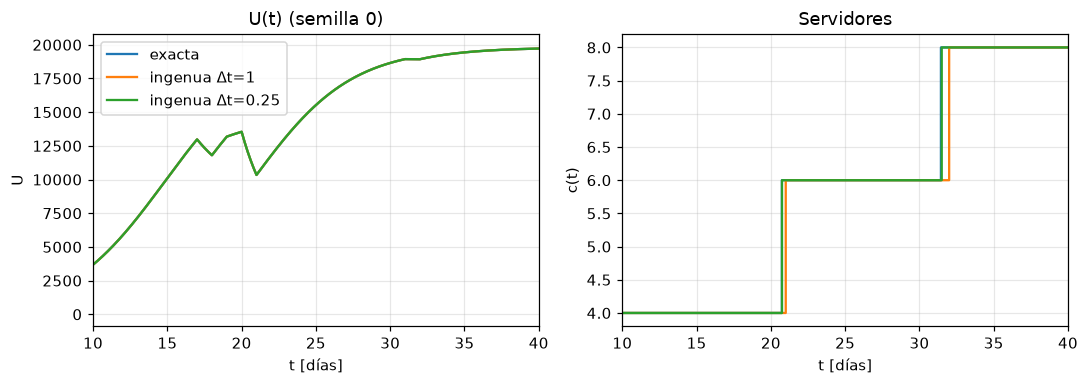

In [14]:
# (b) Tres versiones: exacta, ingenua Δt=1 d e ingenua Δt=0.25 d. Misma semilla de DES (números aleatorios comunes).
versiones = {"exacta": dict(detect="exact"), "ingenua Δt=1": dict(detect="naive", check_dt=1.0),
             "ingenua Δt=0.25": dict(detect="naive", check_dt=0.25)}

def resumen(res, H=1.0):
    return dict(t_pedido=res["orders"][0][0] if res["orders"] else float("nan"),
                t_llegada=res["arrivals"][0] if res["arrivals"] else float("nan"),
                n_pedidos=len(res["orders"]), W_max=res["W_max"], r_max=res["r_max"], U100=res["U_end"], c_end=res["c_end"],
                dias_deg=H * sum(1 for x in res["log"] if x[4] > W_OK))

# una réplica (semilla 0)
una = {k: resumen(simular_hibrido(seed=0, **v)) for k, v in versiones.items()}
for k, v in una.items():
    print(f"{k:16s} pedido={v['t_pedido']:.3f} llegada={v['t_llegada']:.3f} W_max={v['W_max']:.3f} U(100)={v['U100']:.1f} c={v['c_end']}")
RES["t23b_una"] = una

# 20 réplicas independientes por versión
R23 = 20
t0 = time.time()
reps23 = {k: [resumen(simular_hibrido(seed=100 + s, **v)) for s in range(R23)] for k, v in versiones.items()}
print(f"({time.time()-t0:.0f} s)")
tab23 = {}
for k, lst in reps23.items():
    tab23[k] = {m: ic95([x[m] for x in lst]) for m in ["t_pedido", "t_llegada", "W_max", "r_max", "U100", "dias_deg"]}
    print(k, {m: f"{v[0]:.3f}±{v[1]:.3f}" for m, v in tab23[k].items()})
# diferencias pareadas respecto de la exacta
par23 = {}
for k in ["ingenua Δt=1", "ingenua Δt=0.25"]:
    par23[k] = {m: ic95([a[m] - b[m] for a, b in zip(reps23[k], reps23["exacta"])]) for m in ["t_pedido", "t_llegada", "W_max", "U100", "dias_deg"]}
    print("pareada", k, {m: f"{v[0]:+.3f}±{v[1]:.3f}" for m, v in par23[k].items()})
RES["t23b"] = dict(R=R23, tab=tab23, par=par23)

# Con H=1 y D entero el DES solo "ve" c en t=kH, y las tres versiones llegan a la misma ventana: no hay diferencia observable.
# Se repite con H=0.25 d (ventana más fina que el retraso de detección), donde el instante exacto del evento sí se refleja en el DES.
H_F, R23F = 0.25, 10
t0 = time.time()
repsF = {k: [resumen(simular_hibrido(H=H_F, seed=700 + s, **v), H_F) for s in range(R23F)] for k, v in versiones.items()}
print(f"H=0.25 ({time.time()-t0:.0f} s)")
tabF = {k: {m: ic95([x[m] for x in lst]) for m in ["t_pedido", "t_llegada", "W_max", "r_max", "U100", "dias_deg"]} for k, lst in repsF.items()}
parF = {k: {m: ic95([a[m] - b[m] for a, b in zip(repsF[k], repsF["exacta"])]) for m in ["t_pedido", "t_llegada", "W_max", "U100", "dias_deg"]}
        for k in ["ingenua Δt=1", "ingenua Δt=0.25"]}
for k in tabF:
    print("H=0.25", k, {m: f"{v[0]:.3f}±{v[1]:.3f}" for m, v in tabF[k].items()})
for k in parF:
    print("H=0.25 pareada", k, {m: f"{v[0]:+.3f}±{v[1]:.3f}" for m, v in parF[k].items()})
RES["t23b_H025"] = dict(R=R23F, tab=tabF, par=parF)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for k, v in versiones.items():
    r_ = simular_hibrido(seed=0, **v)
    ax[0].plot(r_["t"], r_["U"], label=k); ax[1].plot(r_["t"], r_["c"], label=k, drawstyle="steps-post")
ax[0].set(xlabel="t [días]", ylabel="U", xlim=(10, 40), title="U(t) (semilla 0)"); ax[1].set(xlabel="t [días]", ylabel="c(t)", xlim=(10, 40), title="Servidores")
ax[0].legend(); plt.tight_layout(); plt.show()

In [15]:
# (c) ¿Cuándo hace más daño la detección tardía? Barrido de crecimiento (q) y retraso (D), cascada y lazo cerrado.
# t_sat = días que tarda U en ir de rho=theta a rho=1 (c=4), sin realimentación: si D + retraso_detección > t_sat, hay saturación.
def t_sat(q):
    f = lambda t: float(bass_exacta(t, q=q))
    t1 = optimize.brentq(lambda t: rho_pred(f(t), 4) - THETA, 0.1, 200)
    t2 = optimize.brentq(lambda t: rho_pred(f(t), 4) - 1.0, 0.1, 400)
    return t2 - t1

qs, Ds = [0.2, 0.3, 0.5, 0.8], [1, 3, 5, 8]
SEEDS_G, H_G, T_G = [300, 301], 0.25, 60
def dias_deg(r_):
    return H_G * sum(1 for x in r_["log"] if x[4] > W_OK)
grid23 = []
t0 = time.time()
for q_ in qs:
    for D_ in Ds:
        fila = dict(q=q_, D=D_, t_sat=t_sat(q_))
        for modo, kw in (("cascada", dict(kappa_w=0.0, kappa_r=0.0)), ("lazo", {})):
            dif_W, dif_r, dif_d = [], [], []
            for sd in SEEDS_G:
                e = simular_hibrido(q=q_, delay=D_, T_end=T_G, H=H_G, seed=sd, detect="exact", **kw)
                n = simular_hibrido(q=q_, delay=D_, T_end=T_G, H=H_G, seed=sd, detect="naive", check_dt=1.0, **kw)
                dif_W.append(n["W_max"] - e["W_max"]); dif_r.append(n["r_max"] - e["r_max"]); dif_d.append(dias_deg(n) - dias_deg(e))
            fila[modo] = dict(dW=float(np.mean(dif_W)), dr=float(np.mean(dif_r)), dd=float(np.mean(dif_d)))
        grid23.append(fila)
        print(f"q={q_} D={D_:2d} t_sat={fila['t_sat']:.2f} | cascada dW={fila['cascada']['dW']:+.2f} s dr={fila['cascada']['dr']*100:+.1f}% dd={fila['cascada']['dd']:+.2f} d | "
              f"lazo dW={fila['lazo']['dW']:+.2f} s dd={fila['lazo']['dd']:+.2f} d")
print(f"({time.time()-t0:.0f} s)")
RES["t23c"] = dict(qs=qs, Ds=Ds, grid=grid23, H=H_G, seeds=len(SEEDS_G), T=T_G)

q=0.2 D= 1 t_sat=5.94 | cascada dW=+0.11 s dr=+0.0% dd=+0.38 d | lazo dW=+0.06 s dd=+0.38 d


q=0.2 D= 3 t_sat=5.94 | cascada dW=+0.24 s dr=+0.0% dd=+0.50 d | lazo dW=+0.03 s dd=+0.25 d


q=0.2 D= 5 t_sat=5.94 | cascada dW=+0.80 s dr=+0.5% dd=+0.50 d | lazo dW=+0.00 s dd=+0.12 d


q=0.2 D= 8 t_sat=5.94 | cascada dW=+0.00 s dr=+1.5% dd=+0.62 d | lazo dW=+0.00 s dd=+0.50 d


q=0.3 D= 1 t_sat=3.91 | cascada dW=+0.17 s dr=+0.0% dd=+0.25 d | lazo dW=+0.07 s dd=+0.12 d


...

q=0.5 D= 8 t_sat=2.32 | cascada dW=+0.00 s dr=+0.0% dd=+0.00 d | lazo dW=+0.00 s dd=+0.00 d


q=0.8 D= 1 t_sat=1.44 | cascada dW=+1.15 s dr=+0.7% dd=+0.62 d | lazo dW=+0.11 s dd=+0.50 d


q=0.8 D= 3 t_sat=1.44 | cascada dW=+0.16 s dr=+2.5% dd=+0.62 d | lazo dW=+0.02 s dd=+0.75 d


q=0.8 D= 5 t_sat=1.44 | cascada dW=+0.00 s dr=+0.0% dd=+0.75 d | lazo dW=+0.00 s dd=+1.50 d


q=0.8 D= 8 t_sat=1.44 | cascada dW=+0.00 s dr=+0.0% dd=+0.62 d | lazo dW=+0.00 s dd=+0.38 d
(241 s)


---
# Task 2.4 – Verificación de la interfaz SD ↔ DES

30 ventanas : {'n': 30, 'media': 2999.366666666667, 'var': 4212.2402298850575, 'esperado': 3000.0, 'razon': 1.4043765561235342, 'chi2': 40.71832222222223, 'p': 0.14571922295326642, 'z_media': -0.06333333333332121}
300 ventanas: {'n': 300, 'media': 3000.6566666666668, 'var': 2793.0757079152727, 'esperado': 3000.0, 'razon': 0.9308214894901692, 'chi2': 278.3765455555555, 'p': 0.40307667769380817, 'z_media': 0.2076562330177504}


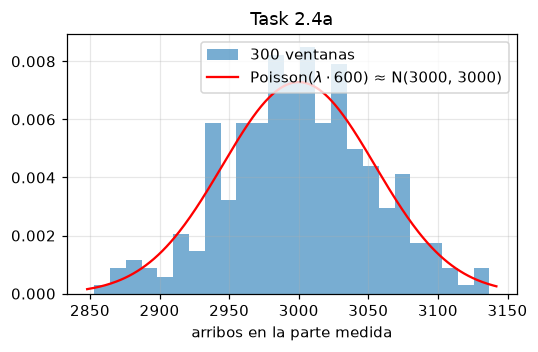

In [16]:
# (a) 30 ventanas con lambda=5 (c=4): arribos generados en la parte medida (600 s) vs. lambda*600 = 3000; media vs. varianza
def conteos(n_vent, lam=5.0, c=4, base=24_000, **kw):
    return np.array([des_window(lam, c, random.Random(base + i), **kw)["n_arr"] for i in range(n_vent)])

dur = T_WIN - T_WARM
n30 = conteos(30)
esp = 5.0 * dur
def disp_test(x, esp):
    """Índice de dispersión var/media y p-valor bilateral de chi^2: (n-1) s^2 / media ~ chi^2_{n-1} si es Poisson."""
    n, m, v = len(x), x.mean(), x.var(ddof=1)
    I = (n - 1) * v / esp
    p = 2 * min(stats.chi2.cdf(I, n - 1), stats.chi2.sf(I, n - 1))
    return dict(n=n, media=float(m), var=float(v), esperado=esp, razon=float(v / m), chi2=float(I), p=float(p),
                z_media=float((m - esp) / math.sqrt(esp / n)))
r30 = disp_test(n30, esp)
n300 = conteos(300, base=25_000)
r300 = disp_test(n300, esp)
RES["t24a"] = dict(r30=r30, r300=r300, ic_media30=ic95(n30))
print("30 ventanas :", r30)
print("300 ventanas:", r300)
fig, ax = plt.subplots(figsize=(5, 3.3))
ax.hist(n300, bins=25, density=True, alpha=.6, label="300 ventanas")
xs = np.arange(int(n300.min()) - 5, int(n300.max()) + 6)
ax.plot(xs, stats.norm.pdf(xs, esp, math.sqrt(esp)), "r-", label="Poisson($\\lambda\\cdot 600$) ≈ N(3000, 3000)")
ax.set(xlabel="arribos en la parte medida", title="Task 2.4a"); ax.legend(); plt.tight_layout(); plt.show()

In [17]:
# (b) Conservación de entidades por ventana. Toda la ventana [0,T]: N0 + A = S + R + N_T.
#     Solo las marcadas (llegadas en [120,720)): A_m = R_m + S_m(≤T) + dentro_m(T).
casos = [(3.0, 4), (5.0, 4), (6.0, 4), (7.0, 4), (5.0, 6), (8.0, 8),        # carga normal
         (9.0, 4), (10.0, 4), (12.0, 4), (10.0, 3), (16.0, 6), (20.0, 8)]    # sobrecarga (rho > 1)
balance = []
for i, (lam, c) in enumerate(casos):
    r_ = des_window(lam, c, random.Random(26_000 + i))
    ok_all = r_["N0"] + r_["A_all"] == r_["S_all"] + r_["R_all"] + r_["N_T"]
    ok_tag = r_["n_arr"] == r_["n_rej"] + r_["n_serv"] + r_["n_in"]
    balance.append(dict(lam=lam, c=c, rho=lam / (c * MU), N0=r_["N0"], A=r_["A_all"], S=r_["S_all"], R=r_["R_all"], NT=r_["N_T"],
                        ok_all=bool(ok_all), Am=r_["n_arr"], Rm=r_["n_rej"], Sm=r_["n_serv"], Im=r_["n_in"], ok_tag=bool(ok_tag)))
    print(f"lam={lam:4.1f} c={c} rho={lam/(c*MU):.2f} | N0={r_['N0']:2d} + A={r_['A_all']:5d} = S={r_['S_all']:5d} + R={r_['R_all']:5d} + N_T={r_['N_T']:2d} -> {ok_all} "
          f"| marcadas: {r_['n_arr']} = {r_['n_rej']} + {r_['n_serv']} + {r_['n_in']} -> {ok_tag}")
assert all(b["ok_all"] and b["ok_tag"] for b in balance)
RES["t24b"] = balance

lam= 3.0 c=4 rho=0.38 | N0= 0 + A= 2124 = S= 2122 + R=    0 + N_T= 2 -> True | marcadas: 1755 = 0 + 1753 + 2 -> True
lam= 5.0 c=4 rho=0.62 | N0= 4 + A= 3695 = S= 3695 + R=    0 + N_T= 4 -> True | marcadas: 3083 = 0 + 3079 + 4 -> True
lam= 6.0 c=4 rho=0.75 | N0= 4 + A= 4370 = S= 4366 + R=    0 + N_T= 8 -> True | marcadas: 3627 = 0 + 3619 + 8 -> True
lam= 7.0 c=4 rho=0.88 | N0= 7 + A= 5081 = S= 5087 + R=    0 + N_T= 1 -> True | marcadas: 4248 = 0 + 4247 + 1 -> True
lam= 5.0 c=6 rho=0.42 | N0= 3 + A= 3567 = S= 3570 + R=    0 + N_T= 0 -> True | marcadas: 2973 = 0 + 2973 + 0 -> True
lam= 8.0 c=8 rho=0.50 | N0= 4 + A= 5707 = S= 5707 + R=    0 + N_T= 4 -> True | marcadas: 4780 = 0 + 4776 + 4 -> True
lam= 9.0 c=4 rho=1.12 | N0=60 + A= 6546 = S= 5817 + R=  739 + N_T=50 -> True | marcadas: 5440 = 579 + 4811 + 50 -> True
lam=10.0 c=4 rho=1.25 | N0=54 + A= 7345 = S= 5685 + R= 1659 + N_T=55 -> True | marcadas: 6091 = 1334 + 4702 + 55 -> True
lam=12.0 c=4 rho=1.50 | N0=58 + A= 8721 = S= 5610 + R= 31

In [18]:
# (c) Sesgo del calentamiento: tres reglas para la ventana, comparadas con el valor estacionario exacto de M/M/c/K
reglas = {"A) estacionaria + descarta 120 s (adoptada)": dict(init="stationary", warm=120.0),
          "B) vacía + descarta 120 s": dict(init="empty", warm=120.0),
          "C) vacía, sin descartar": dict(init="empty", warm=0.0)}
cargas = [(4.0, 4), (6.4, 4), (7.6, 4), (10.0, 4)]       # rho = 0.5, 0.8, 0.95, 1.25
NR = 300
sesgo = []
t0 = time.time()
for lam, c in cargas:
    th = mmcK_theory(lam, c, K_CAP)
    fila = dict(lam=lam, c=c, rho=lam / (c * MU), W_th=th["W"], r_th=th["r"], reglas={})
    for nombre, kw in reglas.items():
        rs_ = [des_window(lam, c, random.Random(27_000 + i), **kw) for i in range(NR)]
        mW, hW = ic95([r["W"] for r in rs_]); mr, hr = ic95([r["r"] for r in rs_])
        fila["reglas"][nombre] = dict(W=mW, W_ic=hW, r=mr, r_ic=hr, sesgo_W=(mW - th["W"]) / th["W"], sesgo_r=mr - th["r"])
        print(f"rho={fila['rho']:.2f} {nombre:45s} W={mW:.4f}±{hW:.4f} (teoría {th['W']:.4f}, sesgo {100*(mW-th['W'])/th['W']:+.2f}%)  r={mr:.4f}±{hr:.4f} (teoría {th['r']:.4f})")
    sesgo.append(fila)
print(f"({time.time()-t0:.0f} s)")
RES["t24c"] = dict(NR=NR, filas=sesgo)

rho=0.50 A) estacionaria + descarta 120 s (adoptada)   W=0.5441±0.0020 (teoría 0.5435, sesgo +0.12%)  r=0.0000±0.0000 (teoría 0.0000)


rho=0.50 B) vacía + descarta 120 s                     W=0.5447±0.0020 (teoría 0.5435, sesgo +0.23%)  r=0.0000±0.0000 (teoría 0.0000)


rho=0.50 C) vacía, sin descartar                       W=0.5442±0.0018 (teoría 0.5435, sesgo +0.13%)  r=0.0000±0.0000 (teoría 0.0000)


rho=0.80 A) estacionaria + descarta 120 s (adoptada)   W=0.8678±0.0100 (teoría 0.8728, sesgo -0.57%)  r=0.0000±0.0000 (teoría 0.0000)


rho=0.80 B) vacía + descarta 120 s                     W=0.8692±0.0095 (teoría 0.8728, sesgo -0.41%)  r=0.0000±0.0000 (teoría 0.0000)


...

rho=0.95 B) vacía + descarta 120 s                     W=2.3409±0.0697 (teoría 2.3425, sesgo -0.07%)  r=0.0025±0.0004 (teoría 0.0026)


rho=0.95 C) vacía, sin descartar                       W=2.2744±0.0618 (teoría 2.3425, sesgo -2.91%)  r=0.0023±0.0004 (teoría 0.0026)


rho=1.25 A) estacionaria + descarta 120 s (adoptada)   W=7.0119±0.0173 (teoría 7.0000, sesgo +0.17%)  r=0.2005±0.0018 (teoría 0.2000)


rho=1.25 B) vacía + descarta 120 s                     W=7.0019±0.0165 (teoría 7.0000, sesgo +0.03%)  r=0.1998±0.0017 (teoría 0.2000)


rho=1.25 C) vacía, sin descartar                       W=6.8404±0.0162 (teoría 7.0000, sesgo -2.28%)  r=0.1921±0.0016 (teoría 0.2000)
(25 s)


---
# Contraste posterior de las predicciones 1.1a y 1.1b con el modelo ya verificado
(No modifica las predicciones: solo las compara con los resultados. La 1.1c pertenece al Task 3 y no se evalúa aquí.)

(34 s)
cascada (kappa=0) {'U100': '19801.338±0.000', 'W_max': '4.536±0.337', 'r_max': '0.028±0.006', 't_pedido': '15.738±0.000', 'c_end': '8.000±0.000', 't_llegada1': '20.738±0.000', 'n_pedidos': '2.000±0.000', 't_pedido2': '20.738±0.000', 'c_min_max': (8, 8)}
lazo cerrado {'U100': '19801.338±0.000', 'W_max': '1.050±0.060', 'r_max': '0.000±0.000', 't_pedido': '15.738±0.000', 'c_end': '8.000±0.000', 't_llegada1': '20.738±0.000', 'n_pedidos': '2.000±0.000', 't_pedido2': '25.332±0.366', 'c_min_max': (8, 8)}
lazo - cascada (pareado): {'U100': '-0.0000±0.0000', 'W_max': '-3.4857±0.3492', 'r_max': '-0.0283±0.0060'}


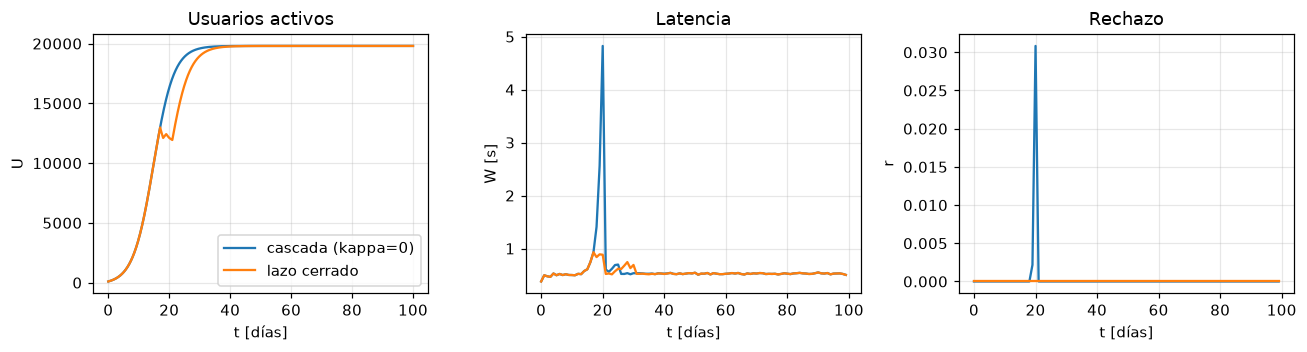

In [19]:
R11 = 20
t0 = time.time()
cmp11 = {}
for nombre, kw in (("cascada (kappa=0)", dict(kappa_w=0.0, kappa_r=0.0)), ("lazo cerrado", {})):
    cmp11[nombre] = [simular_hibrido(seed=500 + s, **kw) for s in range(R11)]
print(f"({time.time()-t0:.0f} s)")
tab11 = {}
for nombre, lst in cmp11.items():
    tab11[nombre] = dict(U100=ic95([x["U_end"] for x in lst]), W_max=ic95([x["W_max"] for x in lst]), r_max=ic95([x["r_max"] for x in lst]),
                         t_pedido=ic95([x["orders"][0][0] for x in lst]), c_end=ic95([x["c_end"] for x in lst]),
                         t_llegada1=ic95([x["arrivals"][0] for x in lst]), n_pedidos=ic95([len(x["orders"]) for x in lst]),
                         t_pedido2=ic95([x["orders"][1][0] for x in lst if len(x["orders"]) > 1]),
                         c_min_max=(int(min(x["c_end"] for x in lst)), int(max(x["c_end"] for x in lst))))
    print(nombre, {k: (f"{v[0]:.3f}±{v[1]:.3f}" if isinstance(v[0], float) else v) for k, v in tab11[nombre].items()})
RES["t11"] = dict(R=R11, tab=tab11)
par11 = {m: ic95([a[k] - b[k] for a, b in zip(cmp11["lazo cerrado"], cmp11["cascada (kappa=0)"])]) for m, k in
         [("U100", "U_end"), ("W_max", "W_max"), ("r_max", "r_max")]}
RES["t11"]["par"] = par11
print("lazo - cascada (pareado):", {m: f"{v[0]:+.4f}±{v[1]:.4f}" for m, v in par11.items()})

fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for nombre, lst in cmp11.items():
    x = lst[0]
    ax[0].plot(x["t"], x["U"], label=nombre)
    ax[1].plot([l[0] for l in x["log"]], [l[4] for l in x["log"]], label=nombre)
    ax[2].plot([l[0] for l in x["log"]], [l[5] for l in x["log"]], label=nombre)
ax[0].set(xlabel="t [días]", ylabel="U", title="Usuarios activos"); ax[1].set(xlabel="t [días]", ylabel="W [s]", title="Latencia"); ax[2].set(xlabel="t [días]", ylabel="r", title="Rechazo")
ax[0].legend(); plt.tight_layout(); plt.show()

---
# Task 3 (Entrega final)
Reutiliza `simular_hibrido`, `des_window`, `mmcK_theory`, `ic95`... definidas arriba (ejecutar antes las celdas de las capas SD, DES e híbrido).
Parámetros de ejecución: cambia `R31` y `R33` a 3 para una prueba rápida; los valores del enunciado son 20.

In [20]:
# ============================ Task 3 · utilidades comunes ============================
import csv, os
RES3 = {}
R31, R33 = 20, 20            # réplicas (el enunciado pide >= 20)

def wilson(k, n, z=1.959964):
    """Intervalo de Wilson al 95 % para una proporción k/n (mejor que Wald con n pequeño)."""
    if n == 0: return (float("nan"),) * 3
    ph = k / n
    den = 1 + z * z / n
    cen = (ph + z * z / (2 * n)) / den
    hw = z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / den
    return ph, max(0.0, cen - hw), min(1.0, cen + hw)

def des_det(lam, c, rng=None, **kw):
    """DES 'determinista': en vez de simular, devuelve W y r EXACTOS de M/M/c/K (esperanza del DES).
    Sirve para aislar el efecto del retraso del lazo (sin ruido del DES) en el Task 3.1b."""
    th = mmcK_theory(lam, c, K_CAP)
    return dict(W=th["W"], r=th["r"], n_arr=0, n_rej=0)

## Task 3.1 – Sensibilidad a la ventana de intercambio $H$
(a) Híbrido completo con $H\in\{0.25,0.5,1,2,4,7\}$, `R31` réplicas, 100 días. Error relativo cuadrático medio (RRMSE) por réplica:
$\mathrm{RRMSE}=\sqrt{\frac{1}{N}\sum_{t=1}^{N}\left(\frac{U_H(t)-U_{ref}(t)}{U_{ref}(t)}\right)^2}$ sobre la rejilla diaria $t=1,\dots,100$, con referencia $H=0.25$ (misma réplica/semilla).
Como "piso de ruido" se añade una segunda tanda **independiente** de $H=0.25$ comparada con la referencia.

In [21]:
# ============================ Task 3.1a ============================
H_LIST = [0.25, 0.5, 1.0, 2.0, 4.0, 7.0]
GRID = np.arange(1.0, 101.0, 1.0)             # rejilla diaria común para comparar trayectorias

def U_on_grid(res):
    return np.interp(GRID, res["t"], res["U"])

def rrmse(Uh, Uref):
    return float(np.sqrt(np.mean(((Uh - Uref) / Uref) ** 2)))

t0 = time.time()
runs31 = {}
for H in H_LIST:
    runs31[H] = [simular_hibrido(H=H, T_end=100.0, seed=900 + s) for s in range(R31)]
    print(f"H={H}: {time.time()-t0:.0f} s acumulados")
# segunda tanda independiente de H=0.25 (piso de ruido del DES)
runs_floor = [simular_hibrido(H=0.25, T_end=100.0, seed=1900 + s) for s in range(R31)]
print(f"piso de ruido listo ({time.time()-t0:.0f} s)")

ref_traj = [U_on_grid(x) for x in runs31[0.25]]
tab31 = {}
for H in H_LIST:
    err = [rrmse(U_on_grid(runs31[H][i]), ref_traj[i]) for i in range(R31)]
    tab31[H] = dict(U100=ic95([x["U_end"] for x in runs31[H]]),
                    W_max=ic95([x["W_max"] for x in runs31[H]]),
                    r_max=ic95([x["r_max"] for x in runs31[H]]),
                    err=ic95(err), err_raw=err,
                    n_pedidos=ic95([len(x["orders"]) for x in runs31[H]]),
                    t_ped1=ic95([x["orders"][0][0] for x in runs31[H]]))
floor_err = [rrmse(U_on_grid(runs_floor[i]), ref_traj[i]) for i in range(R31)]
tab31["floor"] = dict(err=ic95(floor_err), err_raw=floor_err,
                      U100=ic95([x["U_end"] for x in runs_floor]), W_max=ic95([x["W_max"] for x in runs_floor]))

print(f"{'H':>6} | {'U(100)':>20} | {'W_max [s]':>16} | {'r_max':>14} | {'RRMSE [%]':>16}")
for H in H_LIST:
    r = tab31[H]
    print(f"{H:>6} | {r['U100'][0]:>10.1f}±{r['U100'][1]:<8.1f} | {r['W_max'][0]:>8.3f}±{r['W_max'][1]:<6.3f} | "
          f"{r['r_max'][0]:>6.4f}±{r['r_max'][1]:<6.4f} | {100*r['err'][0]:>8.3f}±{100*r['err'][1]:<6.3f}")
f = tab31["floor"]
print(f"{'0.25*':>6} | {f['U100'][0]:>10.1f}±{f['U100'][1]:<8.1f} | {f['W_max'][0]:>8.3f}±{f['W_max'][1]:<6.3f} | {'':>14} | {100*f['err'][0]:>8.3f}±{100*f['err'][1]:<6.3f}   (* = 2.ª tanda independiente = piso de ruido)")
RES3["t31"] = {str(H): {k: v for k, v in tab31[H].items() if k != "err_raw"} for H in H_LIST}
RES3["t31"]["floor"] = {k: v for k, v in tab31["floor"].items() if k != "err_raw"}

H=0.25: 67 s acumulados


H=0.5: 101 s acumulados


H=1.0: 117 s acumulados


H=2.0: 125 s acumulados


H=4.0: 129 s acumulados


H=7.0: 131 s acumulados


piso de ruido listo (198 s)
     H |               U(100) |        W_max [s] |          r_max |        RRMSE [%]
  0.25 |    19801.3±0.0      |    1.042±0.033  | 0.0000±0.0000 |    0.000±0.000 
   0.5 |    19801.3±0.0      |    1.091±0.056  | 0.0001±0.0003 |    1.537±0.413 
   1.0 |    19801.3±0.0      |    1.025±0.047  | 0.0000±0.0000 |    2.052±0.525 
   2.0 |    19801.3±0.0      |    1.338±0.159  | 0.0004±0.0008 |   10.116±3.151 
   4.0 |    19801.3±0.0      |    4.357±0.655  | 0.0301±0.0093 |   38.340±4.631 
   7.0 |    19801.3±0.0      |    0.611±0.013  | 0.0000±0.0000 |    5.992±0.179 
 0.25* |    19801.3±0.0      |    1.093±0.038  |                |    0.840±0.102    (* = 2.ª tanda independiente = piso de ruido)


### Task 3.1b – Forma del error y experimento para separar *ruido del DES* de *retraso del lazo*
Experimento adicional: se repite el barrido con un DES **determinista** (`des_det`, entrega $W$ y $r$ exactos de M/M/$c$/$K$). Sin ruido, todo error contra $H=0.25$ es retraso del lazo (y de los eventos).
Además, se compara el error de las réplicas (con ruido) contra el piso de ruido de $H=0.25$.

DES determinista, RRMSE [%] vs H=0.25   : {0.25: 0.0, 0.5: 0.4355, 1.0: 0.684, 2.0: 10.9501, 4.0: 41.0343, 7.0: 6.0553}
DES determinista, RRMSE [%] vs H=0.0625 : {0.25: 0.0421, 0.5: 0.445, 1.0: 0.7003, 2.0: 10.9519, 4.0: 41.0348, 7.0: 6.0592, 0.125: 0.013}
U(100) determinista: {0.25: 19801.34, 0.5: 19801.34, 1.0: 19801.34, 2.0: 19801.34, 4.0: 19801.34, 7.0: 19801.34}
pedidos (t, motivo) determinista H=1: [(15.738, 'cruce'), (24.426, 'cruce')] | llegadas: [20.738, 29.426]

Error medio (con ruido) por H: [0.0, 1.537, 2.052, 10.116, 38.34, 5.992]
¿monótono creciente? False
piso de ruido (H=0.25 vs H=0.25 indep.): 0.840 ± 0.102 %
H=0.5: error 1.537 ± 0.413 %  | supera el piso (IC inferior > IC superior del piso)? True
H=1.0: error 2.052 ± 0.525 %  | supera el piso (IC inferior > IC superior del piso)? True
H=2.0: error 10.116 ± 3.151 %  | supera el piso (IC inferior > IC superior del piso)? True
H=4.0: error 38.340 ± 4.631 %  | supera el piso (IC inferior > IC superior del piso)? True
H=7.

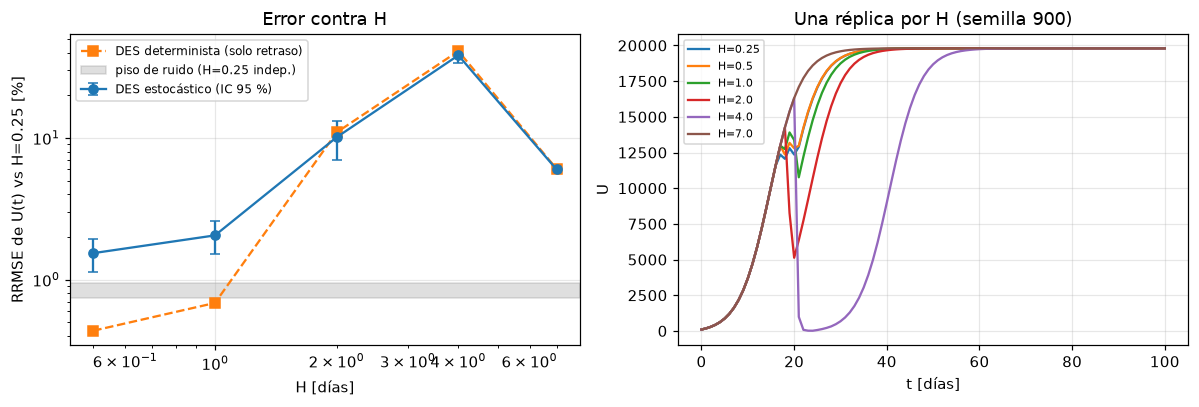


% pgfplots (error con ruido, %):   (0.5,1.5373) (1.0,2.0519) (2.0,10.1159) (4.0,38.3403) (7.0,5.9917)
% pgfplots (error determinista, %): (0.5,0.4355) (1.0,0.6840) (2.0,10.9501) (4.0,41.0343) (7.0,6.0553)


In [22]:
# ============================ Task 3.1b ============================
# Barrido determinista (monkeypatch temporal de des_window: simular_hibrido lo busca como global)
_des_orig = des_window
des_window = des_det
try:
    det_runs = {H: simular_hibrido(H=H, T_end=100.0, seed=0) for H in H_LIST + [0.125, 0.0625]}
finally:
    des_window = _des_orig
det_ref = U_on_grid(det_runs[0.25])
det_err = {H: rrmse(U_on_grid(det_runs[H]), det_ref) for H in H_LIST}
det_ref2 = U_on_grid(det_runs[0.0625])                 # referencia más fina, para ver el error "verdadero" del retraso
det_err_fino = {H: rrmse(U_on_grid(det_runs[H]), det_ref2) for H in H_LIST + [0.125]}
print("DES determinista, RRMSE [%] vs H=0.25   :", {H: round(100 * v, 4) for H, v in det_err.items()})
print("DES determinista, RRMSE [%] vs H=0.0625 :", {H: round(100 * v, 4) for H, v in det_err_fino.items()})
print("U(100) determinista:", {H: round(float(det_runs[H]['U_end']), 2) for H in H_LIST})
print("pedidos (t, motivo) determinista H=1:", [(round(a, 3), b) for a, b in det_runs[1.0]["orders"]],
      "| llegadas:", [round(a, 3) for a in det_runs[1.0]["arrivals"]])

# monotonía y comparación con el piso de ruido
med = [tab31[H]["err"][0] for H in H_LIST]
print("\nError medio (con ruido) por H:", [round(100 * m, 3) for m in med])
print("¿monótono creciente?", all(med[i] <= med[i + 1] for i in range(len(med) - 1)))
fl = tab31["floor"]["err"]
print(f"piso de ruido (H=0.25 vs H=0.25 indep.): {100*fl[0]:.3f} ± {100*fl[1]:.3f} %")
for H in H_LIST[1:]:
    e = tab31[H]["err"]
    print(f"H={H}: error {100*e[0]:.3f} ± {100*e[1]:.3f} %  | supera el piso (IC inferior > IC superior del piso)? {e[0]-e[1] > fl[0]+fl[1]}")
# W_max es un estadístico extremo: crece con el número de ventanas (menor H => más muestras)
print("\nnº de ventanas DES por réplica y W_max:", {H: (int(round(100 / H)), round(tab31[H]['W_max'][0], 3)) for H in H_LIST})

# --- Figura: error vs H ---
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
Hs = H_LIST[1:]
ax[0].errorbar(Hs, [100 * tab31[H]["err"][0] for H in Hs], yerr=[100 * tab31[H]["err"][1] for H in Hs], marker="o", capsize=3, label="DES estocástico (IC 95 %)")
ax[0].plot(Hs, [100 * det_err[H] for H in Hs], "s--", label="DES determinista (solo retraso)")
ax[0].axhspan(100 * (fl[0] - fl[1]), 100 * (fl[0] + fl[1]), color="gray", alpha=0.25, label="piso de ruido (H=0.25 indep.)")
ax[0].set(xscale="log", yscale="log", xlabel="H [días]", ylabel="RRMSE de U(t) vs H=0.25 [%]", title="Error contra H"); ax[0].legend(fontsize=8)
for H in H_LIST:
    ax[1].plot(np.arange(0, 101), np.interp(np.arange(0, 101), runs31[H][0]["t"], runs31[H][0]["U"]), label=f"H={H}")
ax[1].set(xlabel="t [días]", ylabel="U", title="Una réplica por H (semilla 900)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig("fig_task31_error_vs_H.png", dpi=150); plt.show()

# coordenadas listas para pegar en pgfplots del informe
print("\n% pgfplots (error con ruido, %):  ", " ".join(f"({H},{100*tab31[H]['err'][0]:.4f})" for H in Hs))
print("% pgfplots (error determinista, %):", " ".join(f"({H},{100*det_err[H]:.4f})" for H in Hs))
RES3["t31b"] = dict(det_err={str(H): v for H, v in det_err.items()}, det_err_fino={str(H): v for H, v in det_err_fino.items()},
                    monotono=bool(all(med[i] <= med[i + 1] for i in range(len(med) - 1))))

### Task 3.1c – Criterio de confianza
Se reporta la primera $H$ para la que (i) el error con ruido supera el piso de ruido con significancia y (ii) $U(100)$ o $W_{\max}$ salen del IC de $H=0.25$ (criterio de diferencia en métricas de decisión).

In [23]:
# ============================ Task 3.1c ============================
ref = tab31[0.25]
print("Referencia H=0.25:  U(100) = %.1f ± %.1f | W_max = %.3f ± %.3f" % (*ref["U100"], *ref["W_max"]))
crit = {}
for H in H_LIST[1:]:
    r = tab31[H]
    out_U = abs(r["U100"][0] - ref["U100"][0]) > (r["U100"][1] + ref["U100"][1])
    out_W = abs(r["W_max"][0] - ref["W_max"][0]) > (r["W_max"][1] + ref["W_max"][1])
    sup_ruido = r["err"][0] - r["err"][1] > fl[0] + fl[1]
    crit[H] = dict(sup_ruido=bool(sup_ruido), U100_fuera=bool(out_U), Wmax_fuera=bool(out_W), err_pct=100 * r["err"][0])
    print(f"H={H:>4}: error {100*r['err'][0]:6.2f} % | > piso: {sup_ruido!s:5} | U(100) fuera de IC_ref: {out_U!s:5} | W_max fuera de IC_ref: {out_W!s:5}")
RES3["t31c"] = {str(k): v for k, v in crit.items()}

Referencia H=0.25:  U(100) = 19801.3 ± 0.0 | W_max = 1.042 ± 0.033
H= 0.5: error   1.54 % | > piso: True  | U(100) fuera de IC_ref: False | W_max fuera de IC_ref: False
H= 1.0: error   2.05 % | > piso: True  | U(100) fuera de IC_ref: False | W_max fuera de IC_ref: False
H= 2.0: error  10.12 % | > piso: True  | U(100) fuera de IC_ref: True  | W_max fuera de IC_ref: True 
H= 4.0: error  38.34 % | > piso: True  | U(100) fuera de IC_ref: True  | W_max fuera de IC_ref: True 
H= 7.0: error   5.99 % | > piso: True  | U(100) fuera de IC_ref: True  | W_max fuera de IC_ref: True 


## Task 3.3 – Doce políticas de autoescalado
$\theta\in\{0.5,0.6,0.7,0.8\}$, $k\in\{1,2,4\}$ servidores por pedido, `R33` réplicas, 150 días, $H=1$.
**Números aleatorios comunes:** la réplica $s$ usa la misma semilla en las 12 políticas, de modo que las diferencias entre políticas se comparan de forma pareada.
Ingreso neto $=\sum_{d=1}^{150}U(d)-40\sum_{d=1}^{150}c(d)$ (suma diaria al cierre de cada día). $P(r>5\%)$ = proporción de réplicas con algún día cuya $r$ supera 0.05.

In [24]:
# ============================ Task 3.3a ============================
THETAS, KS = [0.5, 0.6, 0.7, 0.8], [1, 2, 4]
T33, DAYS = 150.0, np.arange(1.0, 151.0)

def step_c(res, days):
    """c(d): valor vigente al cierre del día d (función escalón sobre la traza)."""
    idx = np.searchsorted(res["t"], days, side="right") - 1
    return res["c"][idx]

pol_runs, t0 = {}, time.time()
for th in THETAS:
    for k in KS:
        pol_runs[(th, k)] = [simular_hibrido(H=1.0, T_end=T33, theta=th, batch=k, seed=3000 + s) for s in range(R33)]
        print(f"theta={th}, k={k} listo ({time.time()-t0:.0f} s)")

def metrics(res):
    Ud = np.interp(DAYS, res["t"], res["U"])
    cd = step_c(res, DAYS)
    rs = np.array([l[5] for l in res["log"]])
    return dict(ingreso=float(Ud.sum() - 40.0 * cd.sum()), sumU=float(Ud.sum()), sumC=float(cd.sum()),
                any5=bool((rs > 0.05).any()), dias5=int((rs > 0.05).sum()), W_max=res["W_max"], r_max=res["r_max"],
                U150=float(Ud[-1]), c_end=int(res["c_end"]), n_ped=len(res["orders"]),
                t_ped1=res["orders"][0][0] if res["orders"] else float("nan"))

M33 = {pol: [metrics(x) for x in lst] for pol, lst in pol_runs.items()}
POLS = list(M33.keys())
tab33 = {}
for pol in POLS:
    L = M33[pol]
    k_hit = sum(m["any5"] for m in L)
    tab33[pol] = dict(ingreso=ic95([m["ingreso"] for m in L]), sumU=ic95([m["sumU"] for m in L]), sumC=ic95([m["sumC"] for m in L]),
                      p5=wilson(k_hit, len(L)), dias5=ic95([m["dias5"] for m in L]), W_max=ic95([m["W_max"] for m in L]),
                      r_max=ic95([m["r_max"] for m in L]), c_end=ic95([m["c_end"] for m in L]), U150=ic95([m["U150"] for m in L]))
print(f"\n{'theta':>5} {'k':>2} | {'ingreso neto (x1e6)':>22} | {'sum c':>10} | {'P(r>5%) [IC Wilson]':>24} | {'días r>5%':>10} | {'W_max':>12} | c_fin")
for pol in POLS:
    r = tab33[pol]
    print(f"{pol[0]:>5} {pol[1]:>2} | {r['ingreso'][0]/1e6:>9.4f} ± {r['ingreso'][1]/1e6:<8.4f} | {r['sumC'][0]:>10.0f} | "
          f"{r['p5'][0]:>6.2f} [{r['p5'][1]:.2f},{r['p5'][2]:.2f}] | {r['dias5'][0]:>10.2f} | {r['W_max'][0]:>6.2f}±{r['W_max'][1]:<5.2f} | {r['c_end'][0]:.1f}")
RES3["t33"] = {f"{p[0]}_{p[1]}": v for p, v in tab33.items()}

theta=0.5, k=1 listo (27 s)


theta=0.5, k=2 listo (55 s)


theta=0.5, k=4 listo (82 s)


theta=0.6, k=1 listo (109 s)


theta=0.6, k=2 listo (136 s)


...

theta=0.7, k=2 listo (215 s)


theta=0.7, k=4 listo (241 s)


theta=0.8, k=1 listo (265 s)


theta=0.8, k=2 listo (290 s)


theta=0.8, k=4 listo (314 s)

theta  k |    ingreso neto (x1e6) |      sum c |      P(r>5%) [IC Wilson] |  días r>5% |        W_max | c_fin
  0.5  1 |    2.6059 ± 0.0027   |       1317 |   0.00 [0.00,0.16] |       0.00 |   1.00±0.05  | 10.0
  0.5  2 |    2.6107 ± 0.0036   |       1360 |   0.00 [0.00,0.16] |       0.00 |   1.00±0.05  | 10.0
  0.5  4 |    2.6002 ± 0.0035   |       1621 |   0.00 [0.00,0.16] |       0.00 |   1.00±0.05  | 12.0
  0.6  1 |    2.5991 ± 0.0029   |       1204 |   0.00 [0.00,0.16] |       0.00 |   1.03±0.04  | 9.0
  0.6  2 |    2.6047 ± 0.0027   |       1341 |   0.00 [0.00,0.16] |       0.00 |   1.02±0.05  | 10.0
  0.6  4 |    2.5949 ± 0.0027   |       1586 |   0.00 [0.00,0.16] |       0.00 |   1.02±0.05  | 12.0
  0.7  1 |    2.5938 ± 0.0053   |       1078 |   0.00 [0.00,0.16] |       0.00 |   1.09±0.07  | 8.0
  0.7  2 |    2.6071 ± 0.0030   |       1101 |   0.00 [0.00,0.16] |       0.00 |   1.05±0.05  | 8.0
  0.7  4 |    2.6067 ± 0.0030   |       1120 |   0.00 [

### Task 3.3b – ¿Qué políticas no se distinguen?
Comparación **pareada** (mismas semillas) del ingreso neto: prueba $t$ pareada para las 66 parejas con corrección de Holm; en $P(r>5\%)$ prueba exacta de McNemar (binomial sobre discordantes) contra la mejor política. Se marcan como indistinguibles las que no rechazan $H_0$ al 5 % tras la corrección.

In [25]:
# ============================ Task 3.3b ============================
from itertools import combinations
def holm(pvals):
    """Corrección de Holm (control de la tasa de error por familia). Devuelve p ajustados en el mismo orden."""
    m = len(pvals); order = np.argsort(pvals); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * pvals[i]); adj[i] = min(1.0, run)
    return adj

ing = {pol: np.array([m["ingreso"] for m in M33[pol]]) for pol in POLS}
pairs = list(combinations(POLS, 2))
pv = []
for a, b in pairs:
    d = ing[a] - ing[b]
    pv.append(stats.ttest_1samp(d, 0.0).pvalue if d.std(ddof=1) > 0 else 1.0)
padj = dict(zip(pairs, holm(np.array(pv))))
def padj_of(a, b): return padj[(a, b)] if (a, b) in padj else padj[(b, a)]

best = max(POLS, key=lambda p: tab33[p]["ingreso"][0])
print(f"Mejor ingreso medio: theta={best[0]}, k={best[1]}  ({tab33[best]['ingreso'][0]/1e6:.4f} M)")
print("\nDiferencia pareada de ingreso vs la mejor (IC 95 %) y p ajustado (Holm, 66 comparaciones):")
indist = []
for pol in sorted(POLS, key=lambda p: -tab33[p]["ingreso"][0]):
    if pol == best: continue
    d = ing[best] - ing[pol]; m, h = ic95(d); pa = padj_of(best, pol)
    same = pa >= 0.05
    if same: indist.append(pol)
    print(f"  theta={pol[0]}, k={pol[1]}:  mejor - esta = {m:>12.0f} ± {h:<10.0f}  p_adj={pa:.4f}  {'NO distinguible de la mejor' if same else 'peor (significativo)'}")
print("\nIndistinguibles de la mejor en ingreso:", indist)

# P(r>5%): McNemar exacto contra la política de menor P(r>5%) y contra la mejor en ingreso
a5 = {pol: np.array([m["any5"] for m in M33[pol]]) for pol in POLS}
safest = min(POLS, key=lambda p: (tab33[p]["p5"][0], -tab33[p]["ingreso"][0]))
print(f"\nPolítica con menor P(r>5%): theta={safest[0]}, k={safest[1]}  P={tab33[safest]['p5'][0]:.2f}")
pm = []
for pol in POLS:
    if pol == safest: pm.append(1.0); continue
    b01 = int(((~a5[safest]) & a5[pol]).sum()); b10 = int((a5[safest] & ~a5[pol]).sum()); nd = b01 + b10
    pm.append(stats.binomtest(b01, nd, 0.5).pvalue if nd > 0 else 1.0)
pm_adj = holm(np.array(pm))
for pol, pa in zip(POLS, pm_adj):
    if pol != safest:
        print(f"  theta={pol[0]}, k={pol[1]}: P={tab33[pol]['p5'][0]:.2f}  p_adj(McNemar vs más segura)={pa:.3f}  {'indistinguible' if pa >= 0.05 else 'distinta'}")

# costo vs. beneficio: descomposición del ingreso
print("\nDescomposición: sum U [M usuarios-día] y costo 40*sum c [M]")
for pol in POLS:
    print(f"  theta={pol[0]}, k={pol[1]}: sumU={tab33[pol]['sumU'][0]/1e6:.4f}M  costo={40*tab33[pol]['sumC'][0]/1e6:.4f}M  c_fin={tab33[pol]['c_end'][0]:.1f}")

# guardar tabla CSV y resumen JSON
with open("task33_tabla.csv", "w", newline="") as fcsv:
    w = csv.writer(fcsv); w.writerow(["theta", "k", "ingreso_mean", "ingreso_ic", "sumC_mean", "p5", "p5_lo", "p5_hi", "dias5_mean", "Wmax_mean", "c_end_mean"])
    for pol in POLS:
        r = tab33[pol]
        w.writerow([pol[0], pol[1], r["ingreso"][0], r["ingreso"][1], r["sumC"][0], *r["p5"], r["dias5"][0], r["W_max"][0], r["c_end"][0]])
RES3["t33b"] = dict(best=list(best), indist_ingreso=[list(p) for p in indist], safest=list(safest))

def _c(o):
    if isinstance(o, dict): return {str(k): _c(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_c(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
with open("resultados_task3.json", "w") as fj: json.dump(_c(RES3), fj, indent=1)
print("\nGuardado: resultados_task3.json, task33_tabla.csv, fig_task31_error_vs_H.png")

Mejor ingreso medio: theta=0.5, k=2  (2.6107 M)

Diferencia pareada de ingreso vs la mejor (IC 95 %) y p ajustado (Holm, 66 comparaciones):
  theta=0.7, k=2:  mejor - esta =         3537 ± 4951        p_adj=1.0000  NO distinguible de la mejor
  theta=0.7, k=4:  mejor - esta =         4000 ± 4890        p_adj=1.0000  NO distinguible de la mejor
  theta=0.5, k=1:  mejor - esta =         4779 ± 2168        p_adj=0.0070  peor (significativo)
  theta=0.6, k=2:  mejor - esta =         5977 ± 3345        p_adj=0.0375  peor (significativo)
  theta=0.5, k=4:  mejor - esta =        10432 ± 35          p_adj=0.0000  peor (significativo)
  theta=0.6, k=1:  mejor - esta =        11545 ± 3814        p_adj=0.0002  peor (significativo)
  theta=0.8, k=4:  mejor - esta =        15381 ± 5641        p_adj=0.0007  peor (significativo)
  theta=0.6, k=4:  mejor - esta =        15781 ± 3344        p_adj=0.0000  peor (significativo)
  theta=0.7, k=1:  mejor - esta =        16914 ± 6271        p_adj=0.0008  peo

### Task 3.3 – Figura de apoyo (trade-off ingreso vs. riesgo de rechazo)

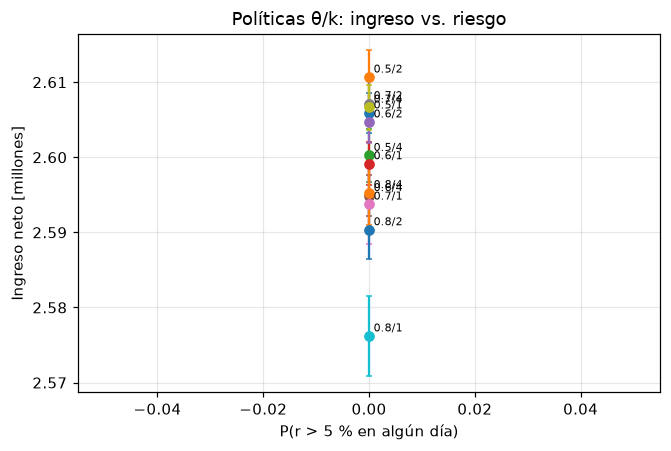

In [26]:
fig, ax = plt.subplots(figsize=(6.2, 4.2))
for pol in POLS:
    r = tab33[pol]
    ax.errorbar(r["p5"][0], r["ingreso"][0] / 1e6, yerr=r["ingreso"][1] / 1e6, fmt="o", capsize=2)
    ax.annotate(f"{pol[0]}/{pol[1]}", (r["p5"][0], r["ingreso"][0] / 1e6), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="P(r > 5 % en algún día)", ylabel="Ingreso neto [millones]", title="Políticas θ/k: ingreso vs. riesgo"); plt.tight_layout()
plt.savefig("fig_task33_tradeoff.png", dpi=150); plt.show()

## Resumen de resultados (JSON) – lo que se transcribe al informe

In [27]:
def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o
print("RESULTADOS_JSON_BEGIN")
print(json.dumps(_clean(RES)))
print("RESULTADOS_JSON_END")

RESULTADOS_JSON_BEGIN
{"t12": {"n_raices": 1, "U_star": 12715.507878244447, "rho_star": 0.7947192423902779, "W_star": 0.8574131468545974, "C_star": 0.5869603325278929, "A_star": 3.1788769695611117, "PK_star": 3.111188470100393e-07, "W_K_star": 0.8574021566290747, "adop": 1403.9592386913964, "aband": 1403.9592386913937, "U_star_K": 12715.564295298234, "U_cuasi_300d": 12715.507878244442, "t_cuasi_95": 16.400000000000002}, "t13": {"U100": 19801.33770227898, "c_end": 8, "W_max": 0.9578499982556427, "r_max": 0.0}, "t21a": {"n": 40, "tab": {"W": {"sim": 0.7552458315718257, "ic": 0.015755819223702446, "teoria": 0.7547169811320755, "cubre": true, "err_rel": 0.0007007268326689491}, "Wq": {"sim": 0.2571996084012034, "ic": 0.014126003959800954, "teoria": 0.25471698113207547, "cubre": true, "err_rel": 0.00974661076027991}, "util": {"sim": 0.7470981728363831, "ic": 0.004555329346963227, "teoria": 0.75, "cubre": true, "err_rel": -0.0038691028848224875}}, "theory": {"A": 3.0, "rho": 0.75, "C": 0.5094